# Mammalian Family Classification from COI-5P DNA Barcodes

**ISA 3 – AI Lab | Data Science and Data Engineering**  
**Students:** Prashant Naik (2607) and Karan Haldankar (2612)

## Project objective
Predict the **mammalian family** from a COI-5P DNA barcode sequence, then investigate individual false-positive and false-negative predictions.

### Important design decisions
- Keep **all family classes**, including families with very few records. Do not impose a minimum class-frequency cutoff.
- Use DNA-derived features as the primary model inputs. Do **not** use `genus`, `species`, `order`, `family`-related taxonomy, process IDs, or location as predictive features.
- Retain specimen/taxonomic metadata separately for later error investigation.
- Exact duplicate sequences must not be split between training and testing. Identical sequences with conflicting family labels are ambiguous and will be flagged and excluded from supervised modelling, while remaining in the audit table.
- A family represented by only one unique sequence cannot be evaluated on a held-out test set while also being present in training. Such families will remain in training and be explicitly reported as not independently testable.

## 1. Imports and configuration
For anyone interested is using this notebook, simply clone the whole repo and run it directly, or download this file as well as the 'DS-EBACMAMM.tsv' adn keep both in same folder and then run the notebook.

Also make sure to first install all required libraries with proper versions using the 'requirement.txt' file.

In [32]:
# If a package is missing, uncomment and run:
# %pip install pandas numpy scikit-learn matplotlib seaborn joblib

from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
TEST_SIZE = 0.20

# Change this if your TSV is stored elsewhere.
DATA_PATH = Path("DS-EBACMAMM.tsv")

# The BOLD export has many columns; load only those needed for the first phase.
REQUIRED_COLUMNS = [
    "processid", "sampleid", "family", "genus", "species",
    "nuc", "marker_code", "country/ocean", "province/state",
    "collection_date_start", "habitat", "identification",
]
print("Data file:", DATA_PATH.resolve())
print("File exists:", DATA_PATH.exists())


Data file: D:\MSC_AI\Fundamentals_Of_AI\Lab\mam_fam_class\DS-EBACMAMM.tsv
File exists: True


## 2. Load the BOLD dataset
The cell checks the for the required file, if not found, update `DATA_PATH` to the location of the TSV. If found then create the dataframe and print the number of rows and the column names.

In [33]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Set DATA_PATH to the full path of your downloaded BOLD TSV."
    )

df = pd.read_csv(DATA_PATH, sep="\t", usecols=lambda c: c in REQUIRED_COLUMNS,
                 low_memory=False, dtype={"processid": "string"})
print("Rows:", len(df))
print("Columns loaded:", df.columns.tolist())
display(df.head(3))


Rows: 52263
Columns loaded: ['processid', 'sampleid', 'family', 'genus', 'species', 'identification', 'collection_date_start', 'country/ocean', 'province/state', 'habitat', 'nuc', 'marker_code']


,processid,sampleid,family,genus,species,identification,collection_date_start,country/ocean,province/state,habitat,nuc,marker_code
0,ABBID001-08,MZB M26934,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Kalimantan Timur,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P
1,ABBID032-09,B09_mw309,Erinaceidae,Echinosorex,Echinosorex gymnura,Echinosorex gymnura,2006-05-01,Indonesia,Kalimantan Tengah,NaN,AACTTATATATAATTTTTGGTGCTTGAGCCGGTATGGTAGGAACGT...,COI-5P
2,ABBID064-09,E05_wc41,Vespertilionidae,Kerivoula,Kerivoula krauensis,Kerivoula krauensis,NaN,Indonesia,Lampung,NaN,ACCCTATATCTACTATTTGGTGCTTGAGCAGGCATAGTGGGAACCG...,COI-5P


## 3. Select mammalian COI-5P records
We select rows where `marker_code` is exactly `COI-5P`, a family label is present, and a nucleotide sequence is available. **No family is removed based on its record count.**

In [34]:
df["marker_code"] = df["marker_code"].astype("string").str.strip()
df["family"] = df["family"].astype("string").str.strip()

coi = df[
    df["marker_code"].eq("COI-5P")
    & df["family"].notna()
    & df["family"].ne("")
    & df["nuc"].notna()
].copy()

print(f"Usable COI-5P records with family labels: {len(coi):,}")
print(f"Distinct family labels: {coi['family'].nunique():,}")
print(f"Distinct species labels (where supplied): {coi['species'].nunique(dropna=True):,}")


Usable COI-5P records with family labels: 39,678
Distinct family labels: 140
Distinct species labels (where supplied): 2,285


## 4. Clean and validate DNA sequences
For the first baseline, retain canonical DNA bases (`A`, `C`, `G`, `T`) and remove whitespace/gaps. Ambiguous bases are counted and flagged; records containing non-ACGT symbols are not used in the initial k-mer model, but are retained in the audit dataframe. This avoids silently treating ambiguous characters as ordinary nucleotides.

In [35]:
def clean_sequence(value):
    if pd.isna(value):
        return ""
    # Uppercase and remove all whitespace (spaces, tabs and line breaks).
    seq = re.sub(r"\s+", "", str(value).upper())
    # Remove alignment gap characters.
    seq = seq.replace("-", "").replace(".", "")
    return seq

coi["sequence_raw"] = coi["nuc"].astype("string")
coi["sequence"] = coi["sequence_raw"].map(clean_sequence)
coi["sequence_length"] = coi["sequence"].str.len()
coi["ambiguous_base_count"] = coi["sequence"].str.count(r"[^ACGT]")
coi["is_acgt_only"] = coi["sequence"].str.fullmatch(r"[ACGT]+").fillna(False)

print("Records with only A/C/G/T:", int(coi["is_acgt_only"].sum()))
print("Records containing ambiguous/non-ACGT symbols:", int((~coi["is_acgt_only"]).sum()))
print("Sequence length summary:")
display(coi["sequence_length"].describe())

# This audit table keeps excluded rows and the reason they were not modelled.
coi["audit_status"] = np.where(coi["is_acgt_only"], "eligible_for_baseline", "ambiguous_or_invalid_sequence")
display(coi[["processid", "family", "marker_code", "sequence_length",
             "ambiguous_base_count", "audit_status"]].head())


Records with only A/C/G/T: 34707
Records containing ambiguous/non-ACGT symbols: 4971
Sequence length summary:


count    39678.000000
mean       725.732648
std        242.058081
min        164.000000
25%        657.000000
50%        657.000000
75%        657.000000
max       1566.000000
Name: sequence_length, dtype: float64

,processid,family,marker_code,sequence_length,ambiguous_base_count,audit_status
0,ABBID001-08,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
1,ABBID032-09,Erinaceidae,COI-5P,657,0,eligible_for_baseline
2,ABBID064-09,Vespertilionidae,COI-5P,657,0,eligible_for_baseline
3,ABBID079-09,Tupaiidae,COI-5P,648,0,eligible_for_baseline
4,ABBM002-05,Vespertilionidae,COI-5P,657,1,ambiguous_or_invalid_sequence


## 5. Inspect all family classes
This is an important decision point. We keep every family, including singleton and very rare families. The plot uses a logarithmic scale so that small classes remain visible beside very large ones.

Number of represented families: 140
Families with 1 record: 14
Families with fewer than 5 records: 38
Families with fewer than 10 records: 57


,family,record_count
0,Phyllostomidae,7456
1,Cricetidae,4388
2,Vespertilionidae,3951
3,Muridae,2847
4,Soricidae,1672
...,...,...
135,Thylacomyidae,1
136,Notoryctidae,1
137,Eupleridae,1
138,Mystacinidae,1


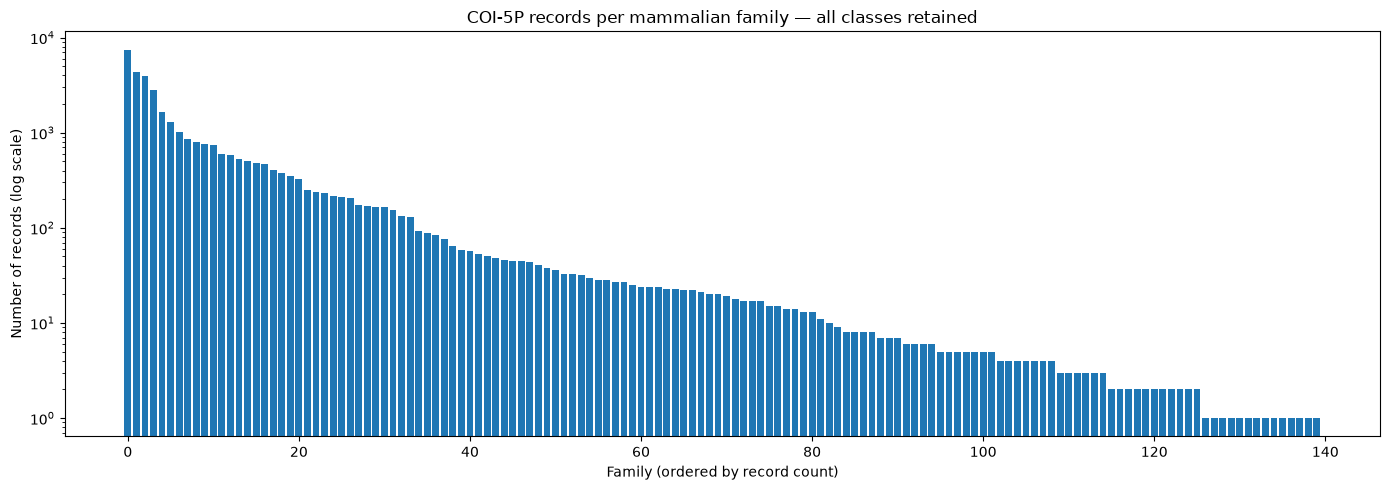

In [36]:
family_counts_all = (
    coi.loc[coi["is_acgt_only"], "family"]
    .value_counts()
    .rename_axis("family")
    .reset_index(name="record_count")
)

print("Number of represented families:", len(family_counts_all))
print("Families with 1 record:", int((family_counts_all.record_count == 1).sum()))
print("Families with fewer than 5 records:", int((family_counts_all.record_count < 5).sum()))
print("Families with fewer than 10 records:", int((family_counts_all.record_count < 10).sum()))
display(family_counts_all)

plt.figure(figsize=(14, 5))
plt.bar(np.arange(len(family_counts_all)), family_counts_all["record_count"])
plt.yscale("log")
plt.xlabel("Family (ordered by record count)")
plt.ylabel("Number of records (log scale)")
plt.title("COI-5P records per mammalian family — all classes retained")
plt.tight_layout()
plt.show()


## 6. Check exact duplicate sequences and conflicting labels
Repeated records with the same DNA sequence can inflate performance if copies appear in both training and testing partitions. We therefore examine exact duplicate sequences and identify sequences associated with conflicting family labels.

Sequences associated with conflicting family labels are excluded from supervised modelling because their labels are ambiguous. All consistent records, including duplicate sequences, are retained in the modelling dataset. This allows us to compare ordinary random splitting with duplicate-grouped and species-grouped validation strategies.

A separate unique-sequence table (`model_df`) is created for inspection, but the actual experiments use `model_records`, which retains consistent duplicate records. The original records remain available in `coi` for auditing and investigation.

In [37]:
eligible = coi.loc[coi["is_acgt_only"]].copy()
eligible["sequence"] = eligible["sequence"].astype(str)

seq_family_counts = eligible.groupby("sequence")["family"].nunique()
conflicting_sequences = set(seq_family_counts[seq_family_counts > 1].index)

print("Eligible source records:", len(eligible))
print("Unique sequences:", eligible["sequence"].nunique())
print("Repeated source records beyond first copy:",
      len(eligible) - eligible["sequence"].nunique())
print("Unique sequences associated with conflicting family labels:",
      len(conflicting_sequences))

# Keep one representative per unique sequence only when its family label is unambiguous.
unambiguous = eligible.loc[~eligible["sequence"].isin(conflicting_sequences)].copy()
model_df = (
    unambiguous.sort_values("processid", na_position="last")
    .drop_duplicates(subset=["sequence"], keep="first")
    .reset_index(drop=True)
)

print("Unique, unambiguous sequences for baseline modelling:", len(model_df))
print("Families remaining in model table:", model_df["family"].nunique())
print("Families represented in eligible records but absent after conflict filtering:",
      sorted(set(eligible["family"]) - set(model_df["family"])))


Eligible source records: 34707
Unique sequences: 17313
Repeated source records beyond first copy: 17394
Unique sequences associated with conflicting family labels: 4
Unique, unambiguous sequences for baseline modelling: 17309
Families remaining in model table: 140
Families represented in eligible records but absent after conflict filtering: []


## 7. Define the three validation strategies

We retain consistent duplicate records in the modelling table so that the grouped experiments are meaningful. Exact DNA sequences associated with conflicting family labels are excluded from supervised modelling, but remain available in the earlier audit table.

- **Validation A — Random split:** randomly divides individual records within each family. Identical sequences may land in both partitions. This is the least restrictive baseline.
- **Validation B.1 — Duplicate-grouped split:** all records with the same exact DNA sequence stay in one partition.
- **Validation B.2 — Species-grouped split:** all records with the same family + species stay together. It also keeps identical sequences together, even if their species labels differ. Missing species values are treated as record-specific groups, while exact-sequence grouping is still enforced.

Each strategy independently trains the same five classifiers: 3 strategies × 5 models = **15 model runs**.

In [38]:
# Prepare modelling records. Keep consistent duplicate records; exclude conflicting sequence labels.
eligible = coi.loc[coi["is_acgt_only"]].copy().reset_index(drop=True)
eligible["sequence"] = eligible["sequence"].astype(str)
eligible["_row_id"] = np.arange(len(eligible))

seq_family_counts = eligible.groupby("sequence")["family"].nunique()
conflicting_sequences = set(seq_family_counts[seq_family_counts > 1].index)

model_records = eligible.loc[
    ~eligible["sequence"].isin(conflicting_sequences)
].copy().reset_index(drop=True)

print("Eligible records:", len(eligible))
print("Unique exact sequences:", eligible["sequence"].nunique())
print("Repeated records beyond first copy:", len(eligible) - eligible["sequence"].nunique())
print("Conflicting sequences excluded:", len(conflicting_sequences))
print("Records retained for modelling (duplicates retained):", len(model_records))
print("Families retained:", model_records["family"].nunique())


Eligible records: 34707
Unique exact sequences: 17313
Repeated records beyond first copy: 17394
Conflicting sequences excluded: 4
Records retained for modelling (duplicates retained): 34688
Families retained: 140


## 8. Define the five classifiers

The same five model definitions and hyperparameters are used in every validation category.

In [39]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from joblib import Parallel, delayed, parallel_config
import time
import os

RANDOM_STATE = 42
TEST_SIZE = 0.20
KMER_SIZE = 4
OUTPUT_DIR = Path("family_classification_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Five independent model jobs will run simultaneously.
N_PARALLEL_JOBS = 5

def make_models():
    return {
        "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
        "Logistic Regression": LogisticRegression(
            max_iter=500, class_weight="balanced",
            solver="saga", tol=1e-3, random_state=RANDOM_STATE
        ),
        "Linear SVM": LinearSVC(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Decision Tree": DecisionTreeClassifier(
            class_weight="balanced", random_state=RANDOM_STATE
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            max_features="sqrt", min_samples_leaf=2,
            # Important: avoid nested parallelism. Joblib parallelizes across models.
            n_jobs=1,
            random_state=RANDOM_STATE
        )
    }

print("Five models:", list(make_models()))
print("Parallel model workers:", N_PARALLEL_JOBS)
print("Logical CPUs reported by OS:", os.cpu_count())


Five models: ['Multinomial Naive Bayes', 'Logistic Regression', 'Linear SVM', 'Decision Tree', 'Random Forest']
Parallel model workers: 5
Logical CPUs reported by OS: 28


## 9. Create the three train/test splits

Splits are made separately within each family. Where a family has only one indivisible group, it remains in training and is listed as not independently testable. Grouped splits may differ from exactly 20% test data because groups cannot be divided.

In [40]:
def random_record_split(data, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    train_ids, test_ids, not_testable = [], [], []
    for family, group in data.groupby("family", sort=True):
        ids = group.index.to_numpy(copy=True)
        rng.shuffle(ids)
        if len(ids) == 1:
            train_ids.extend(ids.tolist())
            not_testable.append(family)
            continue
        n_test = max(1, int(round(len(ids) * test_size)))
        n_test = min(n_test, len(ids) - 1)
        test_ids.extend(ids[:n_test].tolist())
        train_ids.extend(ids[n_test:].tolist())
    return (
        data.loc[train_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        data.loc[test_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        not_testable
    )


def grouped_split(data, group_col, test_size=TEST_SIZE, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    train_ids, test_ids, not_testable = [], [], []
    for family, group in data.groupby("family", sort=True):
        group_values = list(pd.unique(group[group_col]))
        rng.shuffle(group_values)
        if len(group_values) <= 1:
            train_ids.extend(group.index.tolist())
            not_testable.append(family)
            continue
        target = max(1, int(round(len(group) * test_size)))
        selected, selected_count = set(), 0
        for value in group_values[:-1]:
            selected.add(value)
            selected_count += int((group[group_col] == value).sum())
            if selected_count >= target:
                break
        for value in group_values:
            ids = group.index[group[group_col] == value].tolist()
            (test_ids if value in selected else train_ids).extend(ids)
    return (
        data.loc[train_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        data.loc[test_ids].sample(frac=1, random_state=random_state).reset_index(drop=True),
        not_testable
    )


# A: ordinary random record split.
A_train, A_test, A_not_testable = random_record_split(model_records)

# B.1: identical sequence records are indivisible.
b1_data = model_records.copy()
b1_data["_duplicate_group"] = b1_data["sequence"]
B1_train, B1_test, B1_not_testable = grouped_split(b1_data, "_duplicate_group")

# B.2: connected groups join same family+species records and exact sequence records.
# Union-find ensures that neither species nor identical sequences cross partitions.
def species_duplicate_components(data):
    parent = list(range(len(data)))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[rb] = ra

    first_species, first_sequence = {}, {}
    for pos, row in enumerate(data.itertuples()):
        sp = row.species
        if pd.notna(sp) and str(sp).strip():
            key = (str(row.family), str(sp).strip())
            if key in first_species:
                union(pos, first_species[key])
            else:
                first_species[key] = pos
        seq = row.sequence
        if seq in first_sequence:
            union(pos, first_sequence[seq])
        else:
            first_sequence[seq] = pos

    roots = [find(i) for i in range(len(data))]
    root_ids = {root: i for i, root in enumerate(dict.fromkeys(roots))}
    return [root_ids[root] for root in roots]

b2_data = model_records.copy()
b2_data["_species_duplicate_group"] = species_duplicate_components(b2_data)
B2_train, B2_test, B2_not_testable = grouped_split(
    b2_data, "_species_duplicate_group"
)

splits = {
    "Validation A - Random": (A_train, A_test, A_not_testable),
    "Validation B.1 - Duplicate Grouped": (B1_train, B1_test, B1_not_testable),
    "Validation B.2 - Species Grouped": (B2_train, B2_test, B2_not_testable)
}

split_summary_rows = []
for name, (tr, te, nt) in splits.items():
    split_summary_rows.append({
        "validation": name,
        "train_records": len(tr),
        "test_records": len(te),
        "train_families": tr["family"].nunique(),
        "test_families": te["family"].nunique(),
        "families_not_testable": len(nt),
        "actual_test_fraction": len(te) / (len(tr) + len(te))
    })
    print(f"{name}: train={len(tr):,}, test={len(te):,}, not-testable families={len(nt)}")

split_summary_df = pd.DataFrame(split_summary_rows)
display(split_summary_df)


Validation A - Random: train=27,741, test=6,947, not-testable families=14
Validation B.1 - Duplicate Grouped: train=27,552, test=7,136, not-testable families=14
Validation B.2 - Species Grouped: train=24,627, test=10,061, not-testable families=36


,validation,train_records,test_records,train_families,test_families,families_not_testable,actual_test_fraction
0,Validation A - Random,27741,6947,140,126,14,0.200271
1,Validation B.1 - Duplicate Grouped,27552,7136,140,126,14,0.205720
2,Validation B.2 - Species Grouped,24627,10061,140,104,36,0.290043


## 10. Verify leakage conditions

Validation A is intentionally permissive. B.1 must have zero exact-sequence overlap. B.2 must have zero exact-sequence and named family+species overlap.

In [41]:
def check_overlap(train, test, name):
    seq_overlap = set(train["sequence"]) & set(test["sequence"])
    train_species = {
        (str(r.family), str(r.species).strip())
        for r in train.itertuples()
        if pd.notna(r.species) and str(r.species).strip()
    }
    test_species = {
        (str(r.family), str(r.species).strip())
        for r in test.itertuples()
        if pd.notna(r.species) and str(r.species).strip()
    }
    species_overlap = train_species & test_species
    return {
        "validation": name,
        "exact_sequence_overlap": len(seq_overlap),
        "family_species_overlap": len(species_overlap)
    }

leakage_checks_df = pd.DataFrame([
    check_overlap(A_train, A_test, "Validation A - Random"),
    check_overlap(B1_train, B1_test, "Validation B.1 - Duplicate Grouped"),
    check_overlap(B2_train, B2_test, "Validation B.2 - Species Grouped")
])
display(leakage_checks_df)

assert leakage_checks_df.loc[1, "exact_sequence_overlap"] == 0
assert leakage_checks_df.loc[2, "exact_sequence_overlap"] == 0
assert leakage_checks_df.loc[2, "family_species_overlap"] == 0


,validation,exact_sequence_overlap,family_species_overlap
0,Validation A - Random,2151,1091
1,Validation B.1 - Duplicate Grouped,0,964
2,Validation B.2 - Species Grouped,0,0


## 11. Train five models in parallel in each validation category

For each validation category, the k-mer vectorizer is fitted on that category's training partition only. Then the five independent classifiers are trained concurrently using Joblib's process-based `loky` backend.

**Parallelization design**
- Five workers run the five classifiers concurrently.
- Random Forest uses `n_jobs=1` so it does not launch another pool inside a worker (avoids nested parallelism).
- Validation categories run one after another; within each category, its five models run in parallel.
- Joblib limits inner numerical-library threads to reduce CPU oversubscription.
- The reported `parallel_wall_time_sec` is the real elapsed time for the five-model batch. Individual model fit/predict times are also recorded.


In [42]:
def fit_and_evaluate_one_model(
    model_name, model, X_train, y_train, X_test, y_test,
    validation_name, train_count, test_count
):
    """Worker function: fit one classifier and return its predictions and timings."""
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test)
    predict_seconds = time.perf_counter() - start

    test_labels = np.sort(np.unique(y_test))

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        labels=test_labels,
        average="macro",
        zero_division=0
    )

    metrics = {
        "validation": validation_name,
        "model": model_name,
        "accuracy": accuracy_score(y_test, predictions),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "training_time_sec": train_seconds,
        "prediction_time_sec": predict_seconds,
        "train_records": train_count,
        "test_records": test_count
    }

    return model_name, model, predictions, metrics


def run_experiment(validation_name, train_df, test_df):
    print("\\n" + "=" * 75)
    print(validation_name)
    print("=" * 75)

    vectorizer = CountVectorizer(
        analyzer="char",
        ngram_range=(KMER_SIZE, KMER_SIZE),
        lowercase=False,
        dtype=np.float32
    )
    X_train = vectorizer.fit_transform(train_df["sequence"])
    X_test = vectorizer.transform(test_df["sequence"])
    y_train = train_df["family"].to_numpy()
    y_test = test_df["family"].to_numpy()

    print("X_train:", X_train.shape, "| X_test:", X_test.shape)
    print(f"Launching {len(make_models())} model jobs with {N_PARALLEL_JOBS} workers...")

    # Fresh estimator instances for this validation category.
    model_items = list(make_models().items())

    # Process-based parallelism. Limiting inner threads prevents oversubscription.
    parallel_start = time.perf_counter()
    with parallel_config(
        backend="loky",
        n_jobs=N_PARALLEL_JOBS,
        inner_max_num_threads=1
    ):
        worker_results = Parallel(verbose=10)(
            delayed(fit_and_evaluate_one_model)(
                model_name, model, X_train, y_train, X_test, y_test,
                validation_name, len(train_df), len(test_df)
            )
            for model_name, model in model_items
        )
    parallel_wall_time = time.perf_counter() - parallel_start

    fitted, predictions, rows = {}, {}, []
    for model_name, model, pred, metrics in worker_results:
        fitted[model_name] = model
        predictions[model_name] = pred
        rows.append(metrics)
        print(
            f"{model_name}: macro-F1={metrics['macro_f1']:.4f}; "
            f"fit={metrics['training_time_sec']:.2f}s; "
            f"predict={metrics['prediction_time_sec']:.2f}s"
        )

    metrics_df = pd.DataFrame(rows)
    metrics_df["parallel_wall_time_sec"] = parallel_wall_time

    print(f"Five-model parallel wall time: {parallel_wall_time:.2f} seconds")
    print(
        "Sum of individual fit + prediction times (not wall time):",
        f"{(metrics_df['training_time_sec'] + metrics_df['prediction_time_sec']).sum():.2f} seconds"
    )

    return {
        "vectorizer": vectorizer,
        "models": fitted,
        "predictions": predictions,
        "metrics": metrics_df,
        "train_df": train_df.copy(),
        "test_df": test_df.copy(),
        "parallel_wall_time_sec": parallel_wall_time
    }


experiment_results = {}
for validation_name, (tr, te, _) in splits.items():
    experiment_results[validation_name] = run_experiment(validation_name, tr, te)

all_model_results = pd.concat(
    [result["metrics"] for result in experiment_results.values()],
    ignore_index=True
)
print("\\nTotal model runs:", len(all_model_results))
assert len(all_model_results) == 15

parallel_timing_summary = pd.DataFrame([
    {
        "validation": name,
        "parallel_wall_time_sec": result["parallel_wall_time_sec"],
        "sum_individual_fit_predict_sec": (
            result["metrics"]["training_time_sec"]
            + result["metrics"]["prediction_time_sec"]
        ).sum()
    }
    for name, result in experiment_results.items()
])

display(all_model_results.sort_values(["validation", "macro_f1"], ascending=[True, False]))
display(parallel_timing_summary)


\n===========================================================================
Validation A - Random


KeyboardInterrupt: 

## 12. Compare the 15 model runs

Evaluation metrics recalculated using existing predictions.


validation,Validation A - Random,Validation B.1 - Duplicate Grouped,Validation B.2 - Species Grouped
model,,,
Decision Tree,0.652540,0.589215,0.247133
Linear SVM,0.873551,0.857705,0.734921
Logistic Regression,0.846703,0.830402,0.671094
Multinomial Naive Bayes,0.771245,0.789742,0.587012
Random Forest,0.768257,0.749691,0.535563


validation,Validation A - Random,Validation B.1 - Duplicate Grouped,Validation B.2 - Species Grouped
model,,,
Decision Tree,0.942997,0.922646,0.428586
Linear SVM,0.992227,0.991312,0.948315
Logistic Regression,0.976393,0.970992,0.899513
Multinomial Naive Bayes,0.895207,0.901626,0.752808
Random Forest,0.980711,0.973094,0.817215


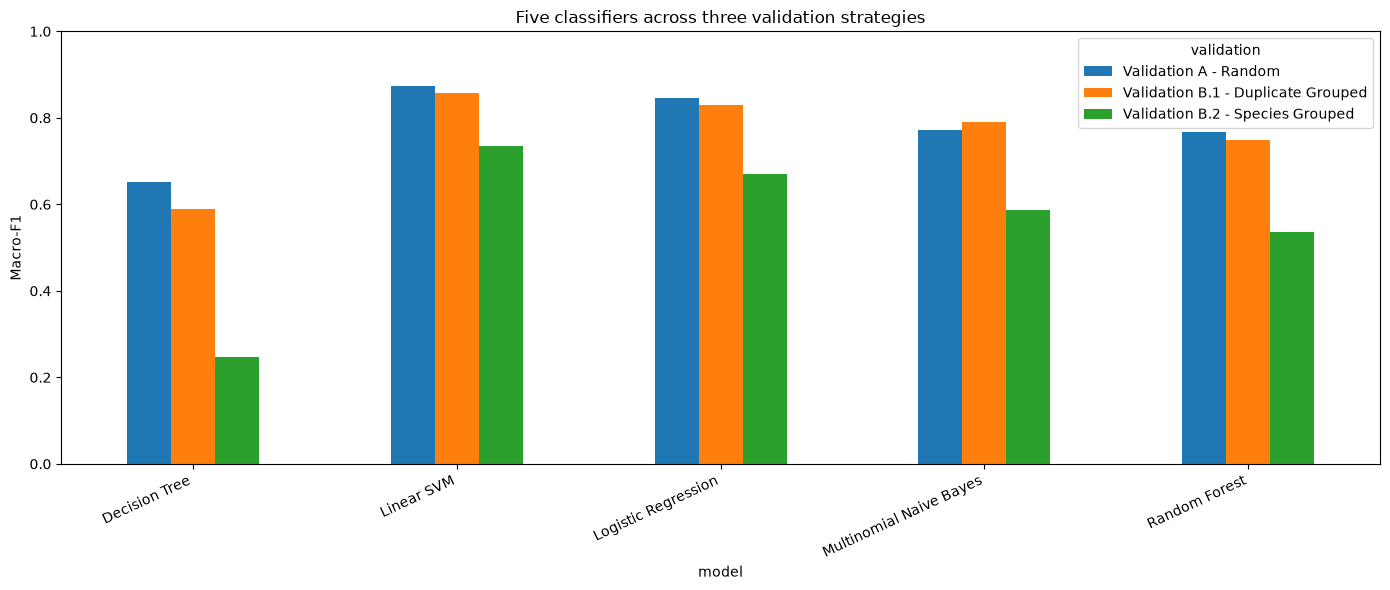

In [ ]:
# Recalculate evaluation metrics using the existing predictions.
# This does not retrain any models.

for validation_name, result in experiment_results.items():

    y_test = result["test_df"]["family"].to_numpy()
    test_labels = np.sort(np.unique(y_test))

    for model_name, predictions in result["predictions"].items():

        precision, recall, f1, _ = precision_recall_fscore_support(
            y_test,
            predictions,
            labels=test_labels,
            average="macro",
            zero_division=0
        )

        mask = (
            (all_model_results["validation"] == validation_name) &
            (all_model_results["model"] == model_name)
        )

        all_model_results.loc[mask, "macro_precision"] = precision
        all_model_results.loc[mask, "macro_recall"] = recall
        all_model_results.loc[mask, "macro_f1"] = f1

print("Evaluation metrics recalculated using existing predictions.")

macro_f1_comparison = all_model_results.pivot(
    index="model", columns="validation", values="macro_f1"
)
accuracy_comparison = all_model_results.pivot(
    index="model", columns="validation", values="accuracy"
)
display(macro_f1_comparison)
display(accuracy_comparison)

ax = macro_f1_comparison.plot(kind="bar", figsize=(14, 6))
ax.set_ylabel("Macro-F1")
ax.set_title("Five classifiers across three validation strategies")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 13. Classification reports for all 15 runs

In [ ]:
for validation_name, result in experiment_results.items():
    print("\\n" + "#" * 75)
    print(validation_name)
    for model_name, pred in result["predictions"].items():
        print(f"\\n--- {model_name} ---")
        print(classification_report(
            result["test_df"]["family"],
            pred,
            labels=sorted(result["test_df"]["family"].unique()),
            zero_division=0
        ))


\n###########################################################################
Validation A - Random
\n--- Multinomial Naive Bayes ---
                   precision    recall  f1-score   support

      Acrobatidae       0.00      0.00      0.00         1
        Ailuridae       1.00      1.00      1.00         1
     Anomaluridae       0.00      0.00      0.00         1
   Antilocapridae       0.00      0.00      0.00         1
          Aotidae       1.00      1.00      1.00         2
         Atelidae       0.25      1.00      0.40         2
       Balaenidae       0.67      1.00      0.80         2
  Balaenopteridae       1.00      0.94      0.97        35
     Bathyergidae       1.00      1.00      1.00         1
          Bovidae       0.99      0.91      0.95       257
     Bradypodidae       1.00      0.80      0.89         5
      Burramyidae       1.00      1.00      1.00         1
    Caenolestidae       0.00      0.00      0.00         1
     Calomyscidae       1.00      1.00 

## 14. Record-level predictions and error analysis tables

In [ ]:
prediction_tables = {}
metadata_columns = [
    c for c in [
        "processid", "sampleid", "family", "genus", "species",
        "country/ocean", "province/state", "collection_date_start",
        "habitat", "sequence", "sequence_length", "ambiguous_base_count"
    ] if c in model_records.columns
]

for validation_name, result in experiment_results.items():
    test_df = result["test_df"].reset_index(drop=True)
    for model_name, pred in result["predictions"].items():
        table = test_df[metadata_columns].copy().rename(columns={"family": "actual_family"})
        table["validation"] = validation_name
        table["model"] = model_name
        table["predicted_family"] = pred
        table["correct"] = table["actual_family"].eq(table["predicted_family"])
        table["error_type"] = np.where(table["correct"], "correct", "misclassified")
        prediction_tables[(validation_name, model_name)] = table

all_predictions = pd.concat(prediction_tables.values(), ignore_index=True)
all_misclassifications = all_predictions.loc[~all_predictions["correct"]].copy()
print("Prediction rows across all runs:", len(all_predictions))
print("Misclassified prediction rows:", len(all_misclassifications))
display(all_misclassifications.head(10))


Prediction rows across all runs: 120720
Misclassified prediction rows: 14797


,processid,sampleid,actual_family,genus,species,country/ocean,province/state,collection_date_start,habitat,sequence,sequence_length,ambiguous_base_count,validation,model,predicted_family,correct,error_type
3,ABGYG1105-08,ROM 119752,Phyllostomidae,Rhinophylla,Rhinophylla pumilio,Guyana,Potaro-Siparuni,2008-08-14,NaN,ACATTGTACTTGTTATTTGGTGCCTGGGCTGGAATAGTAGGCACTG...,657,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
10,GBMTG2704-16,NC_020753,Tragulidae,Tragulus,Tragulus kanchil,NaN,NaN,NaN,NaN,ATGTTCATCAACCGCTGATTATTCTCAACCAACCACAAAGATATTG...,1542,0,Validation A - Random,Multinomial Naive Bayes,Ochotonidae,False,misclassified
17,ABSCA064-06,ROM F38100,Cricetidae,Tylomys,Tylomys watsoni,Panama,NaN,1995-03-01,NaN,ACCCTTTATTTACTATTCGGGGCTTGGGCTGGGATAGTAGGCACTG...,657,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
18,ABGYG188-06,ROM 115757,Phyllostomidae,Rhinophylla,Rhinophylla pumilio,Guyana,Potaro-Siparuni,2004-02-11,NaN,ACATTGTACTTGTTATTTGGTGCCTGGGCTGGAATAGTAGGCACTG...,657,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
21,GBMIN42339-14,JX312053,Soricidae,Crocidura,Crocidura goliath,Gabon,NaN,NaN,NaN,TTCATTACTCGCTGACTCTTTTCCACTAATCATAAGGATATCGGTA...,699,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
42,BPBAT202-14,20120714_10,Phyllostomidae,Glossophaga,Glossophaga soricina,Panama,Chiriqui,2012-07-14,NaN,TTCGGTGCTTGAGCTGGTATAGTGGGAACTGCATTAAGCCTACTTA...,618,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
51,ABRVN415-06,ROM MAM 110957,Vespertilionidae,Scotophilus,Scotophilus kuhlii,Vietnam,Soc Trang,1998-05-26,NaN,ACTCTATACCTACTATTTGGTGCTTGAGCAGGAATAGTGGGAACTG...,657,0,Validation A - Random,Multinomial Naive Bayes,Emballonuridae,False,misclassified
56,GBMA15153-17,KX355030,Phyllostomidae,Erophylla,Erophylla bombifrons,Dominican Republic,NaN,NaN,NaN,ACCCTATATTTACTATTCGGGGCCTGGGCTGGTATAGTAGGCACCG...,657,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified
57,GBMIN42488-14,KC679034,Bovidae,Procapra,Procapra gutturosa,China,NaN,NaN,NaN,TGAGCTGGCATAGTAGGAACCGCCCTAAGCCTATTGATTCGTGCTG...,641,0,Validation A - Random,Multinomial Naive Bayes,Cervidae,False,misclassified
72,GBMA17236-17,KX156600,Canidae,Vulpes,Vulpes vulpes,Turkiye,NaN,NaN,NaN,GGTACTTTATATTTGCTATTCGGAGCATGAGCCGGTATAGTAGGCA...,696,0,Validation A - Random,Multinomial Naive Bayes,Vespertilionidae,False,misclassified


## 15. Per-family one-vs-rest TP, TN, FP and FN

In [ ]:
confusion_rows = []
for (validation_name, model_name), table in prediction_tables.items():
    y_true = table["actual_family"].to_numpy()
    y_pred = table["predicted_family"].to_numpy()
    for family in sorted(set(y_true) | set(y_pred)):
        actual_positive = y_true == family
        predicted_positive = y_pred == family
        confusion_rows.append({
            "validation": validation_name,
            "model": model_name,
            "family": family,
            "TP": int(np.sum(actual_positive & predicted_positive)),
            "TN": int(np.sum(~actual_positive & ~predicted_positive)),
            "FP": int(np.sum(~actual_positive & predicted_positive)),
            "FN": int(np.sum(actual_positive & ~predicted_positive))
        })

per_family_confusion = pd.DataFrame(confusion_rows)
display(per_family_confusion.sort_values(["FN", "FP"], ascending=False).head(30))


,validation,model,family,TP,TN,FP,FN
1694,Validation B.2 - Species Grouped,Decision Tree,Phyllostomidae,689,7944,605,823
1626,Validation B.2 - Species Grouped,Decision Tree,Cricetidae,386,8472,491,712
1295,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Canidae,0,9464,0,597
1618,Validation B.2 - Species Grouped,Decision Tree,Canidae,13,9459,5,584
1360,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Phyllostomidae,1140,8459,90,372
1409,Validation B.2 - Species Grouped,Logistic Regression,Cricetidae,767,8920,43,331
1817,Validation B.2 - Species Grouped,Random Forest,Phyllostomidae,1194,8517,32,318
1371,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Soricidae,56,9725,1,279
1722,Validation B.2 - Species Grouped,Decision Tree,Vespertilionidae,694,8198,894,275
1671,Validation B.2 - Species Grouped,Decision Tree,Mormoopidae,386,9403,7,265


## 16. Export results

In [ ]:
family_counts_all.to_csv(OUTPUT_DIR / "family_record_counts.csv", index=False)
split_summary_df.to_csv(OUTPUT_DIR / "validation_split_summary.csv", index=False)
leakage_checks_df.to_csv(OUTPUT_DIR / "validation_leakage_checks.csv", index=False)
all_model_results.to_csv(OUTPUT_DIR / "all_15_model_results.csv", index=False)
parallel_timing_summary.to_csv(OUTPUT_DIR / "parallel_timing_summary.csv", index=False)
macro_f1_comparison.to_csv(OUTPUT_DIR / "macro_f1_comparison.csv")
accuracy_comparison.to_csv(OUTPUT_DIR / "accuracy_comparison.csv")

all_predictions.drop(columns=["sequence"], errors="ignore").to_csv(
    OUTPUT_DIR / "all_model_predictions.csv", index=False
)
all_misclassifications.drop(columns=["sequence"], errors="ignore").to_csv(
    OUTPUT_DIR / "all_model_misclassifications.csv", index=False
)
per_family_confusion.to_csv(
    OUTPUT_DIR / "per_family_TP_TN_FP_FN_all_experiments.csv", index=False
)

coi[[
    c for c in ["processid", "family", "marker_code", "sequence_length",
                "ambiguous_base_count", "audit_status"] if c in coi.columns
]].to_csv(OUTPUT_DIR / "record_quality_audit.csv", index=False)

eligible.loc[eligible["sequence"].isin(conflicting_sequences)].to_csv(
    OUTPUT_DIR / "conflicting_sequence_family_labels.csv", index=False
)

print("Saved outputs to:", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, "-", f"{p.stat().st_size:,} bytes")


Saved outputs to: D:\MSC_AI\Fundamentals_Of_AI\Lab\mam_fam_class\family_classification_outputs
accuracy_comparison.csv - 470 bytes
all_15_model_results.csv - 3,024 bytes
all_model_misclassifications.csv - 2,514,263 bytes
all_model_predictions.csv - 19,858,619 bytes
conflicting_sequence_family_labels.csv - 44,237 bytes
family_record_counts.csv - 2,275 bytes
macro_f1_comparison.csv - 471 bytes
misclassified_records_for_investigation.csv - 128,732 bytes
model_comparison.csv - 520 bytes
parallel_timing_summary.csv - 267 bytes
per_family_TP_TN_FP_FN.csv - 3,460 bytes
per_family_TP_TN_FP_FN_all_experiments.csv - 132,015 bytes
record_quality_audit.csv - 2,443,943 bytes
test_predictions.csv - 402,846 bytes
validation_leakage_checks.csv - 171 bytes
validation_split_summary.csv - 330 bytes


## 17. Interpretation and limitations

### What the three categories measure
- **Validation A:** performance on randomly held-out records; exact duplicates and other records from the same species may be present in training.
- **Validation B.1:** performance when exact identical DNA sequences are never shared between training and testing.
- **Validation B.2:** performance on held-out species, while also preventing exact identical sequences from crossing partitions.

### Important cautions
1. A family with only one indivisible group cannot be tested while also remaining in training. It is retained in training and reported as not independently testable.
2. Grouped splits can have a test fraction different from 20%, because groups cannot be divided.
3. B.2 groups records together when they share either the same family+species label or the same exact sequence. This can merge multiple species if the same sequence is annotated under different species names.
4. Missing species labels are treated as record-specific groups; identical sequences are still kept together.
5. Validation A is intentionally permissive and may be optimistic if duplicates or near-related records cross partitions.
6. Model metrics are reported on each category's test partition. Do not choose a final model using these test scores and then claim the same score as an unbiased final estimate. A later stage should add validation data or grouped cross-validation for model selection.
7. Only DNA k-mer features are predictive inputs. Taxonomic/specimen metadata is used only for grouping, auditing and error analysis.
8. The current experiments use A/C/G/T-only sequences. Ambiguous nucleotide handling, alternative k-mer sizes, TF-IDF, hyperparameter tuning and biological alignment can be separate future experiments.

### Recommended next steps
1. Run the entire notebook from the beginning.
2. Check `validation_split_summary.csv` and `validation_leakage_checks.csv` first.
3. Compare macro-F1 across all three categories.
4. Inspect misclassified records and family-level FP/FN counts.
5. Then proceed to model-selection design and sequence-similarity analysis.


### Parallel execution
The five classifiers within each validation category are trained concurrently using Joblib (`loky`) with five workers. Validation A, B.1 and B.2 are run sequentially, giving three parallel batches of five model jobs. Random Forest's own `n_jobs` is set to 1 to avoid nested parallelism. The first batch may include process-startup overhead; subsequent batches may be faster because workers can be reused.


## 18.1 Overall Error Analysis

This section examines the overall classification errors produced by all
five machine learning models across the three validation strategies.

The analysis includes correct predictions, misclassified predictions,
accuracy, and multiclass false-positive and false-negative counts.

For multiclass classification, each incorrect prediction contributes
one false negative to its actual family and one false positive to its
predicted family.

In [ ]:

# ============================================================
# SECTION 18.1 - OVERALL ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load saved predictions
predictions_df = pd.read_csv(OUTPUT_DIR / "all_model_predictions.csv")

# ------------------------------------------------------------
# 1. Basic dataset information
# ------------------------------------------------------------

print("TOTAL PREDICTION RECORDS:", len(predictions_df))
print("MODELS:", predictions_df["model"].nunique())
print("VALIDATION STRATEGIES:", predictions_df["validation"].nunique())

print("\nModels:")
print(predictions_df["model"].unique())

print("\nValidation strategies:")
print(predictions_df["validation"].unique())


# ------------------------------------------------------------
# 2. Overall correct and incorrect predictions
# ------------------------------------------------------------

overall_summary = (
    predictions_df
    .groupby(["validation", "model"])
    .agg(
        total_predictions=("correct", "size"),
        correct_predictions=("correct", "sum"),
        misclassified_predictions=(
            "correct",
            lambda x: (~x).sum()
        )
    )
    .reset_index()
)

overall_summary["accuracy"] = (
    overall_summary["correct_predictions"]
    / overall_summary["total_predictions"]
)

overall_summary["error_percentage"] = (
    overall_summary["misclassified_predictions"]
    / overall_summary["total_predictions"]
) * 100

print("\nOVERALL PERFORMANCE AND ERROR SUMMARY")
display(overall_summary)


# ------------------------------------------------------------
# 3. Calculate multiclass FP and FN counts
# ------------------------------------------------------------

# A false negative occurs when the actual family is not predicted.
# A false positive occurs when a family is predicted incorrectly.

error_records = predictions_df[
    predictions_df["correct"] == False
].copy()

error_records["FN_family"] = error_records["actual_family"]
error_records["FP_family"] = error_records["predicted_family"]

# Count false negatives by experiment and actual family
fn_summary = (
    error_records
    .groupby(["validation", "model", "FN_family"])
    .size()
    .reset_index(name="FN")
)

# Count false positives by experiment and predicted family
fp_summary = (
    error_records
    .groupby(["validation", "model", "FP_family"])
    .size()
    .reset_index(name="FP")
)

# Total FP and FN counts for each experiment
total_fn = (
    fn_summary
    .groupby(["validation", "model"])["FN"]
    .sum()
    .reset_index()
)

total_fp = (
    fp_summary
    .groupby(["validation", "model"])["FP"]
    .sum()
    .reset_index()
)

overall_summary = overall_summary.merge(
    total_fn,
    on=["validation", "model"],
    how="left"
)

overall_summary = overall_summary.merge(
    total_fp,
    on=["validation", "model"],
    how="left"
)

overall_summary[["FN", "FP"]] = (
    overall_summary[["FN", "FP"]].fillna(0).astype(int)
)

print("\nOVERALL SUMMARY WITH FP AND FN")
display(overall_summary)


# ------------------------------------------------------------
# 4. Verify FP and FN totals
# ------------------------------------------------------------

print("\nFP/FN CONSISTENCY CHECK")

overall_summary["FP_FN_match"] = (
    overall_summary["FP"] == overall_summary["FN"]
)

display(
    overall_summary[
        ["validation", "model", "FP", "FN", "FP_FN_match"]
    ]
)


# ------------------------------------------------------------
# 5. Export summary
# ------------------------------------------------------------

overall_summary.to_csv(
    OUTPUT_DIR / "overall_error_summary.csv",
    index=False
)

fn_summary.to_csv(
    OUTPUT_DIR / "false_negative_counts_by_family.csv",
    index=False
)

fp_summary.to_csv(
    OUTPUT_DIR / "false_positive_counts_by_family.csv",
    index=False
)

print("\nSection 18.1 results exported successfully.")


TOTAL PREDICTION RECORDS: 120720
MODELS: 5
VALIDATION STRATEGIES: 3

Models:
<StringArray>
['Multinomial Naive Bayes',     'Logistic Regression',
              'Linear SVM',           'Decision Tree',
           'Random Forest']
Length: 5, dtype: str

Validation strategies:
<StringArray>
[             'Validation A - Random', 'Validation B.1 - Duplicate Grouped',
   'Validation B.2 - Species Grouped']
Length: 3, dtype: str

OVERALL PERFORMANCE AND ERROR SUMMARY


,validation,model,total_predictions,correct_predictions,misclassified_predictions,accuracy,error_percentage
0,Validation A - Random,Decision Tree,6947,6551,396,0.942997,5.700302
1,Validation A - Random,Linear SVM,6947,6893,54,0.992227,0.777314
2,Validation A - Random,Logistic Regression,6947,6783,164,0.976393,2.360731
3,Validation A - Random,Multinomial Naive Bayes,6947,6219,728,0.895207,10.479344
4,Validation A - Random,Random Forest,6947,6813,134,0.980711,1.928890
5,Validation B.1 - Duplicate Grouped,Decision Tree,7136,6584,552,0.922646,7.735426
6,Validation B.1 - Duplicate Grouped,Linear SVM,7136,7074,62,0.991312,0.868834
7,Validation B.1 - Duplicate Grouped,Logistic Regression,7136,6929,207,0.970992,2.900785
8,Validation B.1 - Duplicate Grouped,Multinomial Naive Bayes,7136,6434,702,0.901626,9.837444
9,Validation B.1 - Duplicate Grouped,Random Forest,7136,6944,192,0.973094,2.690583



OVERALL SUMMARY WITH FP AND FN


,validation,model,total_predictions,correct_predictions,misclassified_predictions,accuracy,error_percentage,FN,FP
0,Validation A - Random,Decision Tree,6947,6551,396,0.942997,5.700302,396,396
1,Validation A - Random,Linear SVM,6947,6893,54,0.992227,0.777314,54,54
2,Validation A - Random,Logistic Regression,6947,6783,164,0.976393,2.360731,164,164
3,Validation A - Random,Multinomial Naive Bayes,6947,6219,728,0.895207,10.479344,728,728
4,Validation A - Random,Random Forest,6947,6813,134,0.980711,1.928890,134,134
5,Validation B.1 - Duplicate Grouped,Decision Tree,7136,6584,552,0.922646,7.735426,552,552
6,Validation B.1 - Duplicate Grouped,Linear SVM,7136,7074,62,0.991312,0.868834,62,62
7,Validation B.1 - Duplicate Grouped,Logistic Regression,7136,6929,207,0.970992,2.900785,207,207
8,Validation B.1 - Duplicate Grouped,Multinomial Naive Bayes,7136,6434,702,0.901626,9.837444,702,702
9,Validation B.1 - Duplicate Grouped,Random Forest,7136,6944,192,0.973094,2.690583,192,192



FP/FN CONSISTENCY CHECK


,validation,model,FP,FN,FP_FN_match
0,Validation A - Random,Decision Tree,396,396,True
1,Validation A - Random,Linear SVM,54,54,True
2,Validation A - Random,Logistic Regression,164,164,True
3,Validation A - Random,Multinomial Naive Bayes,728,728,True
4,Validation A - Random,Random Forest,134,134,True
5,Validation B.1 - Duplicate Grouped,Decision Tree,552,552,True
6,Validation B.1 - Duplicate Grouped,Linear SVM,62,62,True
7,Validation B.1 - Duplicate Grouped,Logistic Regression,207,207,True
8,Validation B.1 - Duplicate Grouped,Multinomial Naive Bayes,702,702,True
9,Validation B.1 - Duplicate Grouped,Random Forest,192,192,True



Section 18.1 results exported successfully.


## 18.2 Model-wise False Positive and False Negative Comparison

This section compares the false-positive and false-negative patterns
produced by five classification models across three validation strategies.

The analysis identifies:

1. Families with the highest false-negative counts.
2. Families with the highest false-positive counts.
3. Differences in family-wise errors between models.
4. Whether Linear SVM consistently produces fewer errors for particular families.

False negatives are grouped by actual family, whereas false positives
are grouped by predicted family.

All counts represent prediction instances across experiments, not
necessarily unique DNA sequences.

Total misclassified prediction instances: 14797

FALSE NEGATIVES BY MODEL AND FAMILY


,validation,model,family,FN
0,Validation A - Random,Decision Tree,Acrobatidae,1
1,Validation A - Random,Decision Tree,Anomaluridae,1
2,Validation A - Random,Decision Tree,Antilocapridae,1
3,Validation A - Random,Decision Tree,Aotidae,1
4,Validation A - Random,Decision Tree,Atelidae,2
5,Validation A - Random,Decision Tree,Balaenopteridae,4
6,Validation A - Random,Decision Tree,Bathyergidae,1
7,Validation A - Random,Decision Tree,Bovidae,22
8,Validation A - Random,Decision Tree,Bradypodidae,1
9,Validation A - Random,Decision Tree,Caenolestidae,1



FALSE POSITIVES BY MODEL AND FAMILY


,validation,model,family,FP
0,Validation A - Random,Decision Tree,Anomaluridae,1
1,Validation A - Random,Decision Tree,Atelidae,1
2,Validation A - Random,Decision Tree,Balaenidae,1
3,Validation A - Random,Decision Tree,Balaenopteridae,3
4,Validation A - Random,Decision Tree,Bathyergidae,1
5,Validation A - Random,Decision Tree,Bovidae,15
6,Validation A - Random,Decision Tree,Caenolestidae,2
7,Validation A - Random,Decision Tree,Calomyscidae,1
8,Validation A - Random,Decision Tree,Camelidae,1
9,Validation A - Random,Decision Tree,Canidae,3



TOP 10 FAMILIES WITH MOST FALSE NEGATIVES


,family,FN
0,Phyllostomidae,2352
1,Cricetidae,1950
2,Canidae,1223
3,Soricidae,847
4,Mormoopidae,721
5,Heteromyidae,714
6,Vespertilionidae,649
7,Muridae,506
8,Emballonuridae,478
9,Suidae,446


... (6 outputs left out)


LINEAR SVM - FALSE NEGATIVES


,validation,model,family,FN
104,Validation A - Random,Linear SVM,Cricetidae,8
130,Validation A - Random,Linear SVM,Vespertilionidae,4
105,Validation A - Random,Linear SVM,Dasypodidae,3
116,Validation A - Random,Linear SVM,Muridae,3
122,Validation A - Random,Linear SVM,Phyllostomidae,3
...,...,...,...,...
721,Validation B.2 - Species Grouped,Linear SVM,Peramelidae,1
722,Validation B.2 - Species Grouped,Linear SVM,Petauridae,1
723,Validation B.2 - Species Grouped,Linear SVM,Phalangeridae,1
725,Validation B.2 - Species Grouped,Linear SVM,Phocoenidae,1



LINEAR SVM - FALSE POSITIVES


,validation,model,family,FP
113,Validation A - Random,Linear SVM,Sciuridae,6
104,Validation A - Random,Linear SVM,Muridae,5
93,Validation A - Random,Linear SVM,Echimyidae,3
97,Validation A - Random,Linear SVM,Heteromyidae,3
85,Validation A - Random,Linear SVM,Bovidae,2
...,...,...,...,...
616,Validation B.2 - Species Grouped,Linear SVM,Platacanthomyidae,1
622,Validation B.2 - Species Grouped,Linear SVM,Talpidae,1
623,Validation B.2 - Species Grouped,Linear SVM,Tapiridae,1
624,Validation B.2 - Species Grouped,Linear SVM,Thryonomyidae,1


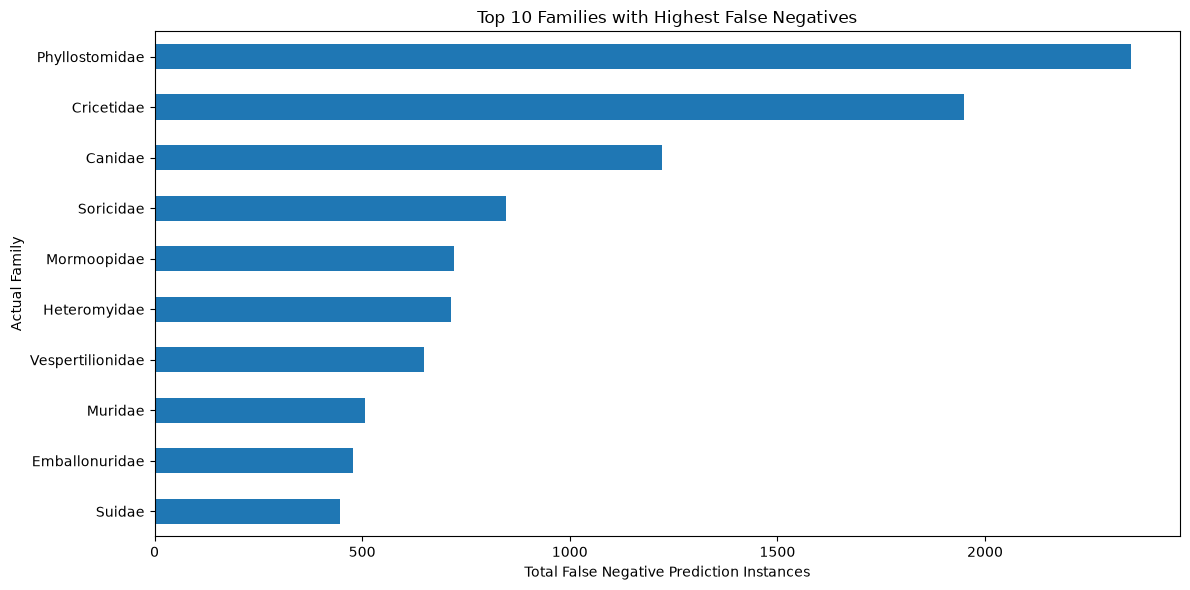

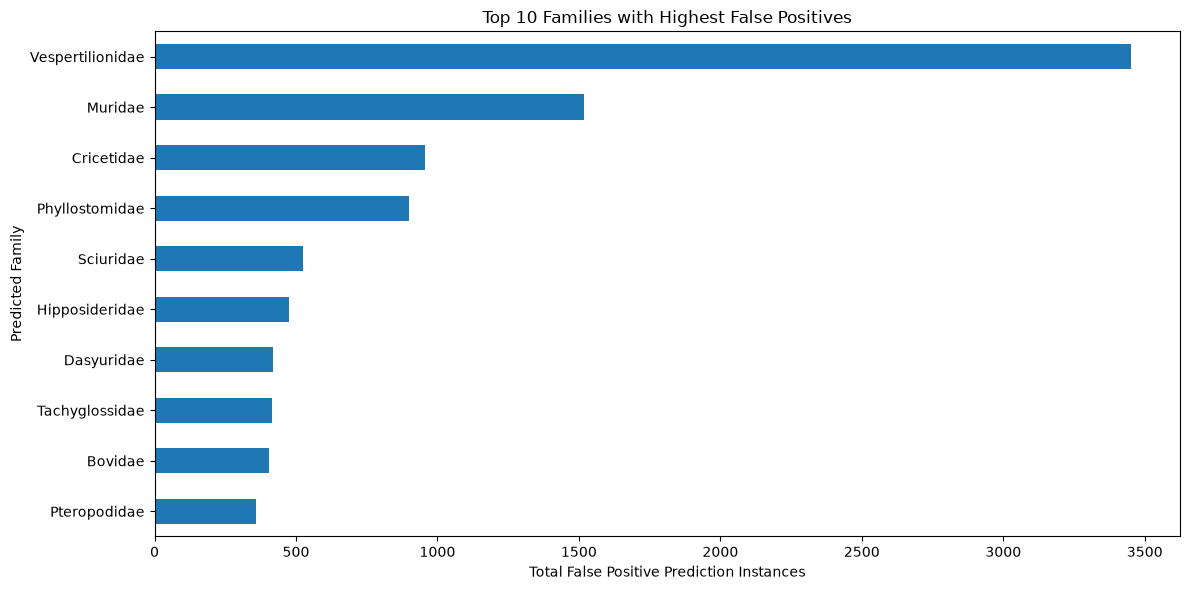


Section 18.2 results exported successfully.


In [ ]:

# ============================================================
# SECTION 18.2 - MODEL-WISE FP/FN COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Extract misclassified prediction records
# ------------------------------------------------------------

errors_df = predictions_df[
    predictions_df["correct"] == False
].copy()

print("Total misclassified prediction instances:", len(errors_df))


# ------------------------------------------------------------
# 2. Calculate False Negatives by actual family
# ------------------------------------------------------------

fn_by_model = (
    errors_df
    .groupby(["validation", "model", "actual_family"])
    .size()
    .reset_index(name="FN")
    .rename(columns={"actual_family": "family"})
)

print("\nFALSE NEGATIVES BY MODEL AND FAMILY")
display(fn_by_model.head(20))


# ------------------------------------------------------------
# 3. Calculate False Positives by predicted family
# ------------------------------------------------------------

fp_by_model = (
    errors_df
    .groupby(["validation", "model", "predicted_family"])
    .size()
    .reset_index(name="FP")
    .rename(columns={"predicted_family": "family"})
)

print("\nFALSE POSITIVES BY MODEL AND FAMILY")
display(fp_by_model.head(20))


# ------------------------------------------------------------
# 4. Identify top 10 FN families across all experiments
# ------------------------------------------------------------

top_fn_families = (
    fn_by_model
    .groupby("family")["FN"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 FAMILIES WITH MOST FALSE NEGATIVES")
display(top_fn_families.reset_index())


# ------------------------------------------------------------
# 5. Identify top 10 FP families across all experiments
# ------------------------------------------------------------

top_fp_families = (
    fp_by_model
    .groupby("family")["FP"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTOP 10 FAMILIES WITH MOST FALSE POSITIVES")
display(top_fp_families.reset_index())


# ------------------------------------------------------------
# 6. Compare FN counts across all 15 experiments
# ------------------------------------------------------------

fn_comparison = (
    fn_by_model[
        fn_by_model["family"].isin(top_fn_families.index)
    ]
    .pivot_table(
        index="family",
        columns=["validation", "model"],
        values="FN",
        aggfunc="sum",
        fill_value=0
    )
)

print("\nTOP FN FAMILIES - COMPARISON ACROSS 15 EXPERIMENTS")
display(fn_comparison)


# ------------------------------------------------------------
# 7. Compare FP counts across all 15 experiments
# ------------------------------------------------------------

fp_comparison = (
    fp_by_model[
        fp_by_model["family"].isin(top_fp_families.index)
    ]
    .pivot_table(
        index="family",
        columns=["validation", "model"],
        values="FP",
        aggfunc="sum",
        fill_value=0
    )
)

print("\nTOP FP FAMILIES - COMPARISON ACROSS 15 EXPERIMENTS")
display(fp_comparison)


# ------------------------------------------------------------
# 8. Compare Linear SVM with other models
# ------------------------------------------------------------

linear_svm_fn = fn_by_model[
    fn_by_model["model"] == "Linear SVM"
]

linear_svm_fp = fp_by_model[
    fp_by_model["model"] == "Linear SVM"
]

print("\nLINEAR SVM - FALSE NEGATIVES")
display(
    linear_svm_fn.sort_values(
        ["validation", "FN"],
        ascending=[True, False]
    )
)

print("\nLINEAR SVM - FALSE POSITIVES")
display(
    linear_svm_fp.sort_values(
        ["validation", "FP"],
        ascending=[True, False]
    )
)


# ------------------------------------------------------------
# 9. Visualize top 10 FN families
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

top_fn_families.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Families with Highest False Negatives")
plt.xlabel("Total False Negative Prediction Instances")
plt.ylabel("Actual Family")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Visualize top 10 FP families
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

top_fp_families.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Families with Highest False Positives")
plt.xlabel("Total False Positive Prediction Instances")
plt.ylabel("Predicted Family")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Export results
# ------------------------------------------------------------

fn_by_model.to_csv(
    OUTPUT_DIR / "fn_by_model_and_family.csv",
    index=False
)

fp_by_model.to_csv(
    OUTPUT_DIR / "fp_by_model_and_family.csv",
    index=False
)

fn_comparison.to_csv(
    OUTPUT_DIR / "fn_family_comparison_15_experiments.csv"
)

fp_comparison.to_csv(
    OUTPUT_DIR / "fp_family_comparison_15_experiments.csv"
)

linear_svm_fn.to_csv(
    OUTPUT_DIR / "linear_svm_false_negatives.csv",
    index=False
)

linear_svm_fp.to_csv(
    OUTPUT_DIR / "linear_svm_false_positives.csv",
    index=False
)

print("\nSection 18.2 results exported successfully.")


## 18.3 Validation-wise Error Comparison

This section investigates how classification errors change across the
three validation strategies.

The analysis compares:

1. Total misclassified prediction instances.
2. Error percentage and accuracy.
3. Changes in error percentage between validation strategies.
4. The relative effect of duplicate-grouped and species-grouped validation
   on each classification model.

Error percentages are used alongside raw counts because the test-set
sizes may differ between validation strategies.

VALIDATION-WISE PERFORMANCE SUMMARY


,model,validation,total_predictions,correct_predictions,misclassified_predictions,accuracy,error_percentage
0,Decision Tree,Validation A - Random,6947,6551,396,94.299698,5.700302
1,Decision Tree,Validation B.1 - Duplicate Grouped,7136,6584,552,92.264574,7.735426
2,Decision Tree,Validation B.2 - Species Grouped,10061,4312,5749,42.858563,57.141437
3,Linear SVM,Validation A - Random,6947,6893,54,99.222686,0.777314
4,Linear SVM,Validation B.1 - Duplicate Grouped,7136,7074,62,99.131166,0.868834
5,Linear SVM,Validation B.2 - Species Grouped,10061,9541,520,94.831528,5.168472
6,Logistic Regression,Validation A - Random,6947,6783,164,97.639269,2.360731
7,Logistic Regression,Validation B.1 - Duplicate Grouped,7136,6929,207,97.099215,2.900785
8,Logistic Regression,Validation B.2 - Species Grouped,10061,9050,1011,89.951297,10.048703
9,Multinomial Naive Bayes,Validation A - Random,6947,6219,728,89.520656,10.479344



ERROR PERCENTAGE COMPARISON


validation,Validation A - Random,Validation B.1 - Duplicate Grouped,Validation B.2 - Species Grouped
model,,,
Decision Tree,5.700302,7.735426,57.141437
Linear SVM,0.777314,0.868834,5.168472
Logistic Regression,2.360731,2.900785,10.048703
Multinomial Naive Bayes,10.479344,9.837444,24.719213
Random Forest,1.928890,2.690583,18.278501



INCREASE IN ERROR RATE (PERCENTAGE POINTS)


,Duplicate_Grouped_Increase_pp,Species_Grouped_Increase_pp,Species_vs_Duplicate_Increase_pp
model,,,
Decision Tree,2.035124,51.441135,49.406011
Random Forest,0.761693,16.349611,15.587918
Multinomial Naive Bayes,-0.641900,14.239869,14.881769
Logistic Regression,0.540054,7.687972,7.147918
Linear SVM,0.091520,4.391158,4.299638



RELATIVE INCREASE IN ERROR (%)


,Duplicate_Grouped_Increase_%,Species_Grouped_Increase_%
model,,
Decision Tree,35.702032,902.428193
Linear SVM,11.773896,564.914393
Logistic Regression,22.876535,325.660604
Multinomial Naive Bayes,-6.125380,135.885125
Random Forest,39.488655,847.617518


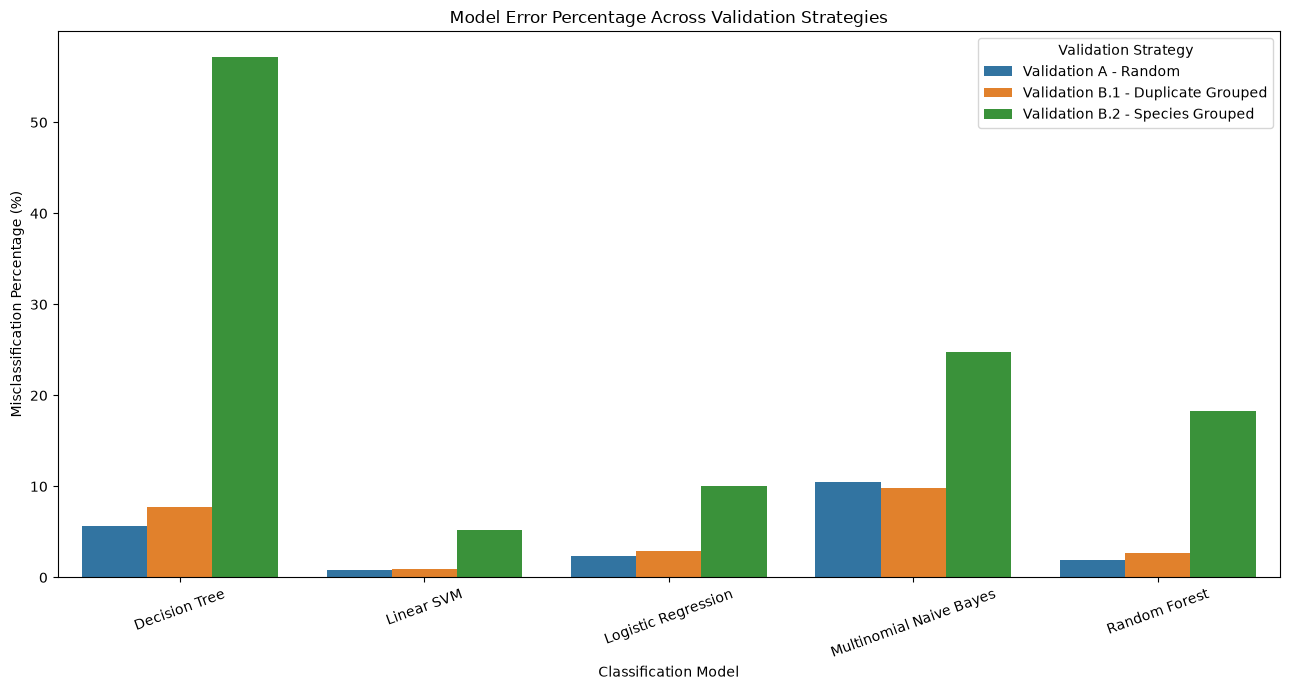

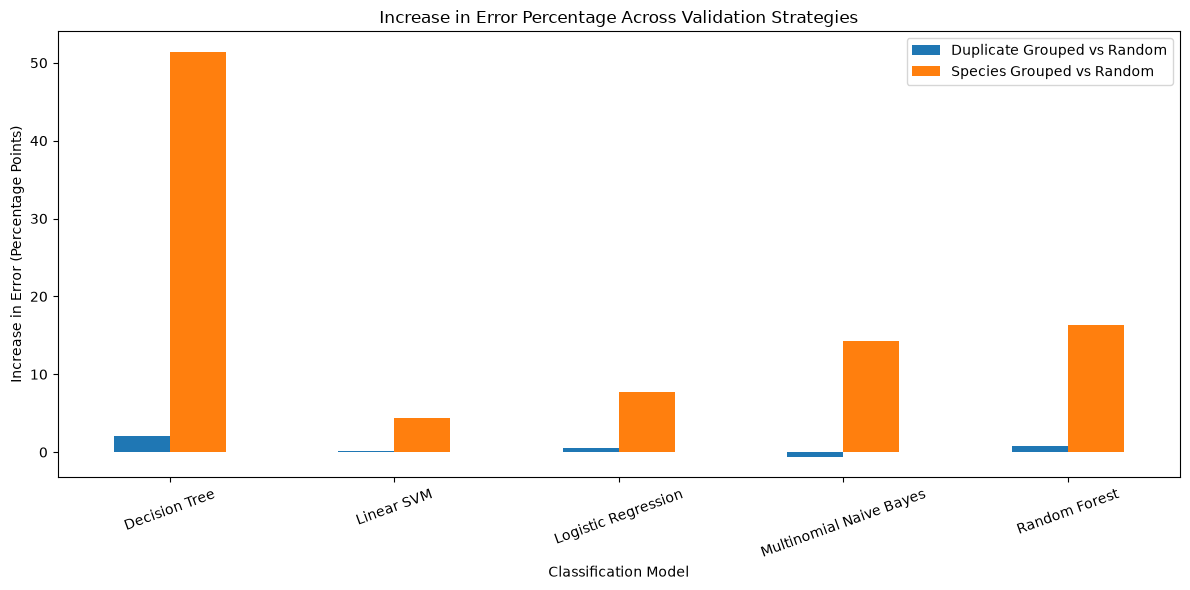


Section 18.3 results exported successfully.


In [43]:

# ============================================================
# SECTION 18.3 - VALIDATION-WISE ERROR COMPARISON
# ============================================================

# ------------------------------------------------------------
# 1. Calculate performance for each model and validation
# ------------------------------------------------------------

validation_summary = (
    predictions_df
    .groupby(["model", "validation"])
    .agg(
        total_predictions=("correct", "size"),
        correct_predictions=("correct", "sum"),
        misclassified_predictions=(
            "correct",
            lambda x: (~x).sum()
        )
    )
    .reset_index()
)

validation_summary["accuracy"] = (
    validation_summary["correct_predictions"]
    / validation_summary["total_predictions"]
) * 100

validation_summary["error_percentage"] = (
    validation_summary["misclassified_predictions"]
    / validation_summary["total_predictions"]
) * 100

print("VALIDATION-WISE PERFORMANCE SUMMARY")
display(
    validation_summary.sort_values(["model", "validation"])
)


# ------------------------------------------------------------
# 2. Compare error percentages across validation strategies
# ------------------------------------------------------------

error_comparison = validation_summary.pivot(
    index="model",
    columns="validation",
    values="error_percentage"
)

print("\nERROR PERCENTAGE COMPARISON")
display(error_comparison)


# ------------------------------------------------------------
# 3. Calculate increase in error percentage points
# ------------------------------------------------------------

random_col = "Validation A - Random"
duplicate_col = "Validation B.1 - Duplicate Grouped"
species_col = "Validation B.2 - Species Grouped"

error_increase = pd.DataFrame(index=error_comparison.index)

error_increase["Duplicate_Grouped_Increase_pp"] = (
    error_comparison[duplicate_col]
    - error_comparison[random_col]
)

error_increase["Species_Grouped_Increase_pp"] = (
    error_comparison[species_col]
    - error_comparison[random_col]
)

error_increase["Species_vs_Duplicate_Increase_pp"] = (
    error_comparison[species_col]
    - error_comparison[duplicate_col]
)

print("\nINCREASE IN ERROR RATE (PERCENTAGE POINTS)")
display(error_increase.sort_values(
    "Species_Grouped_Increase_pp",
    ascending=False
))


# ------------------------------------------------------------
# 4. Calculate relative increase in error percentage
# ------------------------------------------------------------

relative_increase = pd.DataFrame(index=error_comparison.index)

relative_increase["Duplicate_Grouped_Increase_%"] = (
    (
        error_comparison[duplicate_col]
        - error_comparison[random_col]
    )
    / error_comparison[random_col]
) * 100

relative_increase["Species_Grouped_Increase_%"] = (
    (
        error_comparison[species_col]
        - error_comparison[random_col]
    )
    / error_comparison[random_col]
) * 100

print("\nRELATIVE INCREASE IN ERROR (%)")
display(relative_increase)


# ------------------------------------------------------------
# 5. Visualize error percentage across validation strategies
# ------------------------------------------------------------

validation_order = [
    random_col,
    duplicate_col,
    species_col
]

plot_data = validation_summary.copy()

plt.figure(figsize=(13, 7))

sns.barplot(
    data=plot_data,
    x="model",
    y="error_percentage",
    hue="validation",
    order=sorted(plot_data["model"].unique()),
    hue_order=validation_order
)

plt.title("Model Error Percentage Across Validation Strategies")
plt.xlabel("Classification Model")
plt.ylabel("Misclassification Percentage (%)")
plt.xticks(rotation=20)
plt.legend(title="Validation Strategy")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Visualize increase in error percentage points
# ------------------------------------------------------------

error_increase_plot = error_increase[
    [
        "Duplicate_Grouped_Increase_pp",
        "Species_Grouped_Increase_pp"
    ]
].copy()

error_increase_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Increase in Error Percentage Across Validation Strategies")
plt.xlabel("Classification Model")
plt.ylabel("Increase in Error (Percentage Points)")
plt.xticks(rotation=20)
plt.legend([
    "Duplicate Grouped vs Random",
    "Species Grouped vs Random"
])
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Export results
# ------------------------------------------------------------

validation_summary.to_csv(
    OUTPUT_DIR / "validation_wise_error_summary.csv",
    index=False
)

error_comparison.to_csv(
    OUTPUT_DIR / "validation_error_percentage_comparison.csv"
)

error_increase.to_csv(
    OUTPUT_DIR / "validation_error_increase_percentage_points.csv"
)

relative_increase.to_csv(
    OUTPUT_DIR / "validation_relative_error_increase.csv"
)

print("\nSection 18.3 results exported successfully.")


## 18.4 Family-wise Error Analysis

This section investigates classification errors at the mammalian family level.

For each family, model, and validation strategy, the following metrics
are calculated:

- Actual support and predicted support
- True positives, false positives, and false negatives
- Precision and recall
- False-negative rate
- False-positive rate

Both raw error counts and normalized error rates are examined to avoid
misinterpreting families with larger test-set representation as
inherently more difficult to classify.

The analysis also identifies families that consistently show poor
classification performance across different models and validation
strategies.

COMPLETE FAMILY-WISE METRICS


,validation,model,family,actual_support,predicted_support,TP,FN,FP,precision,recall,F1,FN_rate,negative_support,FP_rate,FN_rate_percentage,FP_rate_percentage
0,Validation A - Random,Decision Tree,Acrobatidae,1,0,0,1,0,NaN,0.0,0.0,1.0,6946,0.000000,100.0,0.000000
2,Validation A - Random,Decision Tree,Anomaluridae,1,1,0,1,1,0.0,0.0,0.0,1.0,6946,0.000144,100.0,0.014397
3,Validation A - Random,Decision Tree,Antilocapridae,1,0,0,1,0,NaN,0.0,0.0,1.0,6946,0.000000,100.0,0.000000
5,Validation A - Random,Decision Tree,Atelidae,2,1,0,2,1,0.0,0.0,0.0,1.0,6945,0.000144,100.0,0.014399
8,Validation A - Random,Decision Tree,Bathyergidae,1,1,0,1,1,0.0,0.0,0.0,1.0,6946,0.000144,100.0,0.014397
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1825,Validation B.2 - Species Grouped,Random Forest,Pseudocheiridae,0,5,0,0,5,0.0,NaN,0.0,NaN,10061,0.000497,NaN,0.049697
1829,Validation B.2 - Species Grouped,Random Forest,Rhinopomatidae,0,70,0,0,70,0.0,NaN,0.0,NaN,10061,0.006958,NaN,0.695756
1838,Validation B.2 - Species Grouped,Random Forest,Tarsipedidae,0,6,0,0,6,0.0,NaN,0.0,NaN,10061,0.000596,NaN,0.059636
1840,Validation B.2 - Species Grouped,Random Forest,Thryonomyidae,0,10,0,0,10,0.0,NaN,0.0,NaN,10061,0.000994,NaN,0.099394



TOP 15 FAMILIES BY TOTAL FALSE NEGATIVE COUNT


,family,FN
0,Phyllostomidae,2352
1,Cricetidae,1950
2,Canidae,1223
3,Soricidae,847
4,Mormoopidae,721
5,Heteromyidae,714
6,Vespertilionidae,649
7,Muridae,506
8,Emballonuridae,478
9,Suidae,446



TOP 15 FAMILIES BY AGGREGATED FN RATE


,family,total_actual_support,total_FN,FN_rate_percentage
0,Acrobatidae,15,15,100.000000
1,Cheirogaleidae,15,15,100.000000
2,Chrysochloridae,15,15,100.000000
3,Tragulidae,20,20,100.000000
4,Petauridae,15,15,100.000000
5,Microbiotheriidae,10,10,100.000000
6,Phalangeridae,15,14,93.333333
7,Anomaluridae,15,14,93.333333
8,Phascolarctidae,15,11,73.333333
9,Potoroidae,95,69,72.631579



TOP 15 FAMILIES BY TOTAL FALSE POSITIVE COUNT


,family,FP
0,Vespertilionidae,3452
1,Muridae,1519
2,Cricetidae,955
3,Phyllostomidae,900
4,Sciuridae,525
5,Hipposideridae,476
6,Dasyuridae,418
7,Tachyglossidae,415
8,Bovidae,403
9,Pteropodidae,360



FAMILY-WISE F1 COMPARISON ACROSS EXPERIMENTS


validation       Validation A - Random                                 \
model                    Decision Tree Linear SVM Logistic Regression   
family                                                                  
Acrobatidae                   0.000000   0.000000            0.000000   
Ailuridae                     1.000000   1.000000            1.000000   
Anomaluridae                  0.000000   0.000000            0.000000   
Antilocapridae                0.000000   0.000000            0.000000   
Aotidae                       0.666667   1.000000            1.000000   
...                                ...        ...                 ...   
Ursidae                       0.954545   1.000000            1.000000   
Vespertilionidae              0.943919   0.996829            0.974887   
Viverridae                    0.947368   1.000000            1.000000   
Vombatidae                    0.000000   1.000000            0.000000   
Ziphiidae                     0.833333   1.000000            0.960000   

validation                                              \
model            Multinomial Naive Bayes Random Forest   
family                                                   
Acrobatidae                     0.000000      0.000000   
Ailuridae                       1.000000      1.000000   
Anomaluridae                    0.000000      0.000000   
Antilocapridae                  0.000000      0.000000   
Aotidae                         1.000000      1.000000   
...                                  ...           ...   
Ursidae                         0.976744      1.000000   
Vespertilionidae                0.854402      0.984925   
Viverridae                      1.000000      0.947368   
Vombatidae                      0.000000      0.000000   
Ziphiidae                       0.960000      1.000000   

validation       Validation B.1 - Duplicate Grouped             \
model                                 Decision Tree Linear SVM   
family                                                           
Acrobatidae                                0.000000     0.0000   
Ailuridae                                  0.000000     1.0000   
Anomaluridae                               0.000000     0.0000   
Antilocapridae                             1.000000     1.0000   
Aotidae                                    0.500000     1.0000   
...                                             ...        ...   
Ursidae                                    0.880952     1.0000   
Vespertilionidae                           0.926065     0.9981   
Viverridae                                 0.842105     1.0000   
Vombatidae                                 0.000000     1.0000   
Ziphiidae                                  0.785714     1.0000   

validation                                                                  \
model            Logistic Regression Multinomial Naive Bayes Random Forest   
family                                                                       
Acrobatidae                 0.000000                0.000000      0.000000   
Ailuridae                   1.000000                1.000000      0.666667   
Anomaluridae                0.000000                0.000000      0.000000   
Antilocapridae              1.000000                1.000000      1.000000   
Aotidae                     1.000000                1.000000      1.000000   
...                              ...                     ...           ...   
Ursidae                     1.000000                0.976744      0.976744   
Vespertilionidae            0.955186                0.871186      0.981772   
Viverridae                  0.947368                1.000000      1.000000   
Vombatidae                  1.000000                1.000000      0.000000   
Ziphiidae                   0.962963                1.000000      1.000000   

validation       Validation B.2 - Species Grouped             \
model                               Decision Tree Linear SVM   
family            

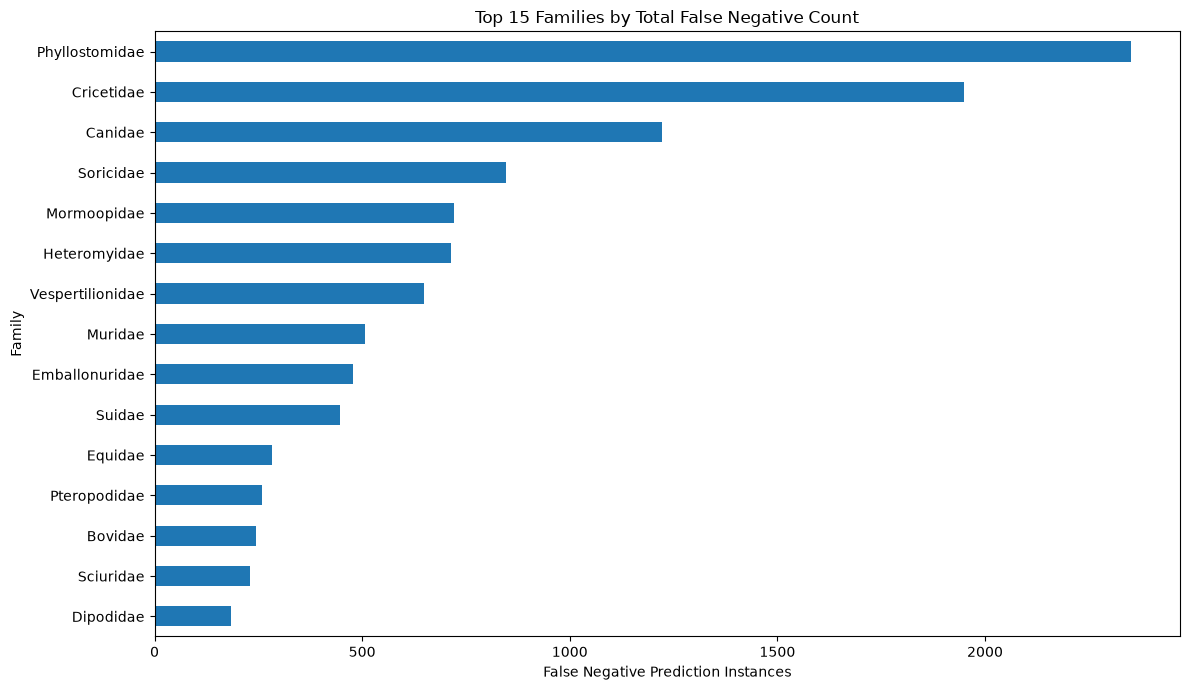

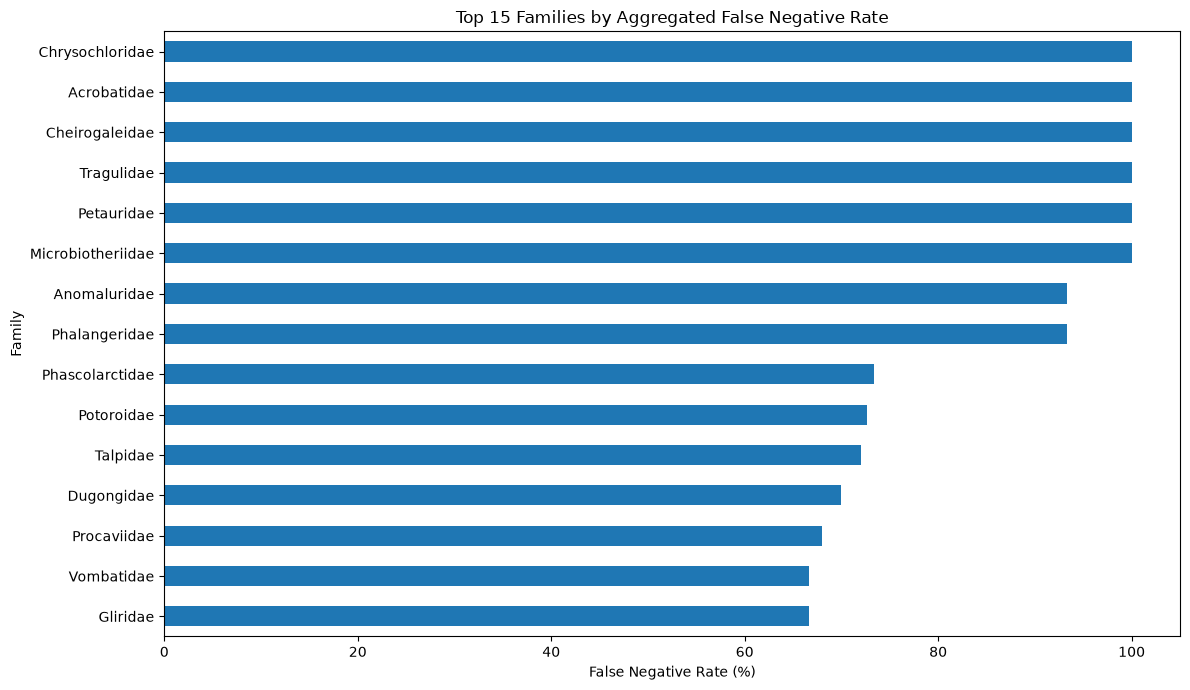


Section 18.4 results exported successfully.


In [44]:

# ============================================================
# SECTION 18.4 - FAMILY-WISE ERROR ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Calculate actual support for each family
# ------------------------------------------------------------

actual_support = (
    predictions_df
    .groupby(["validation", "model", "actual_family"])
    .size()
    .reset_index(name="actual_support")
    .rename(columns={"actual_family": "family"})
)


# ------------------------------------------------------------
# 2. Calculate predicted support for each family
# ------------------------------------------------------------

predicted_support = (
    predictions_df
    .groupby(["validation", "model", "predicted_family"])
    .size()
    .reset_index(name="predicted_support")
    .rename(columns={"predicted_family": "family"})
)


# ------------------------------------------------------------
# 3. Calculate true positives for each family
# ------------------------------------------------------------

true_positives = (
    predictions_df[
        predictions_df["actual_family"]
        == predictions_df["predicted_family"]
    ]
    .groupby(["validation", "model", "actual_family"])
    .size()
    .reset_index(name="TP")
    .rename(columns={"actual_family": "family"})
)


# ------------------------------------------------------------
# 4. Combine all family-level counts
# ------------------------------------------------------------

family_metrics = (
    actual_support
    .merge(
        predicted_support,
        on=["validation", "model", "family"],
        how="outer"
    )
    .merge(
        true_positives,
        on=["validation", "model", "family"],
        how="left"
    )
)

family_metrics[
    ["actual_support", "predicted_support", "TP"]
] = family_metrics[
    ["actual_support", "predicted_support", "TP"]
].fillna(0).astype(int)


# ------------------------------------------------------------
# 5. Calculate FP and FN
# ------------------------------------------------------------

family_metrics["FN"] = (
    family_metrics["actual_support"]
    - family_metrics["TP"]
)

family_metrics["FP"] = (
    family_metrics["predicted_support"]
    - family_metrics["TP"]
)


# ------------------------------------------------------------
# 6. Calculate precision, recall and F1
# ------------------------------------------------------------

family_metrics["precision"] = (
    family_metrics["TP"]
    / family_metrics["predicted_support"].replace(0, np.nan)
)

family_metrics["recall"] = (
    family_metrics["TP"]
    / family_metrics["actual_support"].replace(0, np.nan)
)

family_metrics["F1"] = (
    2 * family_metrics["precision"] * family_metrics["recall"]
    / (
        family_metrics["precision"]
        + family_metrics["recall"]
    )
)

# Fill undefined F1 values with zero
family_metrics["F1"] = family_metrics["F1"].fillna(0)


# ------------------------------------------------------------
# 7. Calculate false-negative and false-positive rates
# ------------------------------------------------------------

family_metrics["FN_rate"] = (
    family_metrics["FN"]
    / family_metrics["actual_support"].replace(0, np.nan)
)

family_metrics["negative_support"] = (
    family_metrics["actual_support"]
    .groupby([family_metrics["validation"], family_metrics["model"]])
    .transform("sum")
    - family_metrics["actual_support"]
)

family_metrics["FP_rate"] = (
    family_metrics["FP"]
    / family_metrics["negative_support"].replace(0, np.nan)
)

family_metrics["FN_rate_percentage"] = (
    family_metrics["FN_rate"] * 100
)

family_metrics["FP_rate_percentage"] = (
    family_metrics["FP_rate"] * 100
)


# ------------------------------------------------------------
# 8. Display complete family-level results
# ------------------------------------------------------------

print("COMPLETE FAMILY-WISE METRICS")
display(
    family_metrics.sort_values(
        ["validation", "model", "FN_rate_percentage"],
        ascending=[True, True, False]
    )
)


# ------------------------------------------------------------
# 9. Identify families with highest FN counts
# ------------------------------------------------------------

top_fn_families = (
    family_metrics
    .groupby("family")["FN"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nTOP 15 FAMILIES BY TOTAL FALSE NEGATIVE COUNT")
display(top_fn_families.reset_index())


# ------------------------------------------------------------
# 10. Identify families with highest FN rates
# ------------------------------------------------------------

# Aggregate actual support and FN across experiments.
# This is a descriptive aggregate of prediction instances.

fn_rate_by_family = (
    family_metrics
    .groupby("family")
    .agg(
        total_actual_support=("actual_support", "sum"),
        total_FN=("FN", "sum")
    )
)

fn_rate_by_family["FN_rate_percentage"] = (
    fn_rate_by_family["total_FN"]
    / fn_rate_by_family["total_actual_support"]
) * 100

# Exclude families with fewer than 10 total prediction instances
# from the ranked rate table to avoid unstable rates.

eligible_fn_rates = fn_rate_by_family[
    fn_rate_by_family["total_actual_support"] >= 10
]

print("\nTOP 15 FAMILIES BY AGGREGATED FN RATE")
display(
    eligible_fn_rates
    .sort_values("FN_rate_percentage", ascending=False)
    .head(15)
    .reset_index()
)


# ------------------------------------------------------------
# 11. Identify families with highest FP counts
# ------------------------------------------------------------

top_fp_families = (
    family_metrics
    .groupby("family")["FP"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nTOP 15 FAMILIES BY TOTAL FALSE POSITIVE COUNT")
display(top_fp_families.reset_index())


# ------------------------------------------------------------
# 12. Compare family-level F1 scores across models
# ------------------------------------------------------------

family_f1_comparison = (
    family_metrics
    .pivot_table(
        index="family",
        columns=["validation", "model"],
        values="F1",
        fill_value=0
    )
)

print("\nFAMILY-WISE F1 COMPARISON ACROSS EXPERIMENTS")
display(family_f1_comparison)


# ------------------------------------------------------------
# 13. Visualize top FN families
# ------------------------------------------------------------

plt.figure(figsize=(12, 7))

top_fn_families.sort_values().plot(kind="barh")

plt.title("Top 15 Families by Total False Negative Count")
plt.xlabel("False Negative Prediction Instances")
plt.ylabel("Family")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Visualize top FN rates
# ------------------------------------------------------------

top_fn_rates_plot = (
    eligible_fn_rates
    .sort_values("FN_rate_percentage", ascending=False)
    .head(15)
)

plt.figure(figsize=(12, 7))

top_fn_rates_plot["FN_rate_percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Families by Aggregated False Negative Rate")
plt.xlabel("False Negative Rate (%)")
plt.ylabel("Family")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 15. Export results
# ------------------------------------------------------------

family_metrics.to_csv(
    OUTPUT_DIR / "family_wise_error_metrics_all_experiments.csv",
    index=False
)

fn_rate_by_family.to_csv(
    OUTPUT_DIR / "family_wise_fn_rate_summary.csv"
)

family_f1_comparison.to_csv(
    OUTPUT_DIR / "family_wise_f1_comparison.csv"
)

print("\nSection 18.4 results exported successfully.")


## 18.5 Common Misclassification Patterns

This section investigates recurring family-level misclassification patterns.

The analysis identifies:
- The most frequent actual-family to predicted-family confusion pairs.
- Confusion pairs that recur across different models.
- Confusion pairs that persist across validation strategies.
- The most frequent confusion pairs for Linear SVM, the strongest-performing model.

The results are based on misclassified prediction instances, not unique DNA sequences.

Total misclassified prediction instances: 14797

TOP 20 MOST FREQUENT FAMILY CONFUSION PAIRS


,actual_family,predicted_family,error_count
1062,Phyllostomidae,Vespertilionidae,1497
277,Cricetidae,Muridae,896
1264,Soricidae,Vespertilionidae,446
141,Canidae,Tachyglossidae,415
129,Canidae,Dasyuridae,351
438,Emballonuridae,Vespertilionidae,293
447,Equidae,Phyllostomidae,221
251,Cricetidae,Dasypodidae,186
600,Heteromyidae,Vespertilionidae,167
795,Mormoopidae,Phyllostomidae,159



TOP 20 CONFUSION PAIRS ACROSS INDIVIDUAL EXPERIMENTS


,validation,model,actual_family,predicted_family,error_count
1561,Validation B.2 - Species Grouped,Decision Tree,Cricetidae,Muridae,421
1506,Validation B.2 - Species Grouped,Decision Tree,Canidae,Tachyglossidae,415
2439,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Phyllostomidae,Vespertilionidae,361
1863,Validation B.2 - Species Grouped,Decision Tree,Phyllostomidae,Vespertilionidae,355
2316,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Canidae,Dasyuridae,351
2678,Validation B.2 - Species Grouped,Random Forest,Phyllostomidae,Vespertilionidae,233
1632,Validation B.2 - Species Grouped,Decision Tree,Equidae,Phyllostomidae,221
2173,Validation B.2 - Species Grouped,Logistic Regression,Cricetidae,Muridae,207
2472,Validation B.2 - Species Grouped,Multinomial Naive Bayes,Soricidae,Vespertilionidae,191
2250,Validation B.2 - Species Grouped,Logistic Regression,Phyllostomidae,Vespertilionidae,162



CONFUSION PAIRS RECURRING ACROSS MODELS


,actual_family,predicted_family,total_errors,experiments_present,models_present,validation_categories
1062,Phyllostomidae,Vespertilionidae,1497,13,5,3
277,Cricetidae,Muridae,896,15,5,3
438,Emballonuridae,Vespertilionidae,293,12,5,3
1032,Phyllostomidae,Hipposideridae,119,11,5,3
1443,Vespertilionidae,Phyllostomidae,98,12,5,3
1435,Vespertilionidae,Molossidae,79,10,5,3
299,Cricetidae,Vespertilionidae,77,12,5,3
580,Heteromyidae,Muridae,75,11,5,3
1431,Vespertilionidae,Hipposideridae,61,11,5,3
435,Emballonuridae,Rhinolophidae,57,9,5,3


... (3 outputs left out)

,validation,actual_family,predicted_family,error_count
180,Validation B.2 - Species Grouped,Phyllostomidae,Vespertilionidae,44
126,Validation B.2 - Species Grouped,Emballonuridae,Vespertilionidae,41
138,Validation B.2 - Species Grouped,Heteromyidae,Emballonuridae,28
221,Validation B.2 - Species Grouped,Ziphiidae,Heteromyidae,20
169,Validation B.2 - Species Grouped,Octodontidae,Cricetidae,19
207,Validation B.2 - Species Grouped,Thyropteridae,Emballonuridae,16
194,Validation B.2 - Species Grouped,Sciuridae,Rhinolophidae,15
195,Validation B.2 - Species Grouped,Soricidae,Emballonuridae,14
111,Validation B.2 - Species Grouped,Cricetidae,Muridae,13
162,Validation B.2 - Species Grouped,Moschidae,Bovidae,13



LINEAR SVM CONFUSION PAIR COMPARISON


validation                          Validation A - Random  \
actual_family     predicted_family                          
Cricetidae        Heteromyidae                        2.0   
Muridae           Rhinocerotidae                      2.0   
Phyllostomidae    Rhinolophidae                       2.0   
Cricetidae        Geomyidae                           1.0   
                  Muridae                             1.0   
Spalacidae        Sciuridae                           1.0   
Heteromyidae      Sciuridae                           1.0   
Muridae           Sciuridae                           1.0   
Acrobatidae       Hipposideridae                      1.0   
Procyonidae       Mustelidae                          1.0   
Cricetidae        Chrysochloridae                     1.0   
                  Erinaceidae                         1.0   
Microbiotheriidae Macropodidae                        1.0   
Phalangeridae     Peramelidae                         1.0   
Talpidae          Muridae                             1.0   
Heteromyidae      Muridae                             1.0   
Octodontidae      Echimyidae                          1.0   
Tragulidae        Bovidae                             1.0   
Cheirogaleidae    Erinaceidae                         1.0   
Erinaceidae       Phyllostomidae                      1.0   
Anomaluridae      Thryonomyidae                       1.0   
Antilocapridae    Bovidae                             1.0   
Bovidae           Muridae                             1.0   
Chrysochloridae   Echimyidae                          1.0   
Cricetidae        Calomyscidae                        1.0   
                  Macroscelididae                     1.0   
Dasypodidae       Cricetidae                          1.0   
                  Hipposideridae                      1.0   
                  Muridae                             1.0   
Dasyuridae        Didelphidae                         1.0   

validation                          Validation B.1 - Duplicate Grouped  \
actual_family     predicted_family                                       
Cricetidae        Heteromyidae                                     1.0   
Muridae           Rhinocerotidae                                   0.0   
Phyllostomidae    Rhinolophidae                                    0.0   
Cricetidae        Geomyidae                                        2.0   
                  Muridae                                          1.0   
Spalacidae        Sciuridae                                        1.0   
Heteromyidae      Sciuridae                                        1.0   
Muridae           Sciuridae                                        1.0   
Acrobatidae       Hipposideridae                                   1.0   
Procyonidae       Mustelidae                                       1.0   
Cricetidae        Chrysochloridae                                  1.0   
                  Erinaceidae                                      1.0   
Microbiotheriidae Macropodidae                                     1.0   
Phalangeridae     Peramelidae                                      1.0   
Talpidae          Muridae                                          0.0   
Heteromyidae      Muridae                                          0.0   
Octodontidae      Echimyidae                                       0.0   
Tragulidae        Bovidae                                          0.0   
Cheirogaleidae    Erinaceidae                                      0.0   
Erinaceidae       Phyllostomidae                                   0.0   
Anomaluridae      Thryonomyidae                                    0.0   
Antilocapridae    Bovidae                                          0.0   
Bovidae           Muridae                                          0.0   
Chrysochloridae   Echimyidae                                       0.0   
Cricetidae        Calomyscidae                                     0.0   
                  Macroscelididae                

<Figure size 1200x800 with 0 Axes>

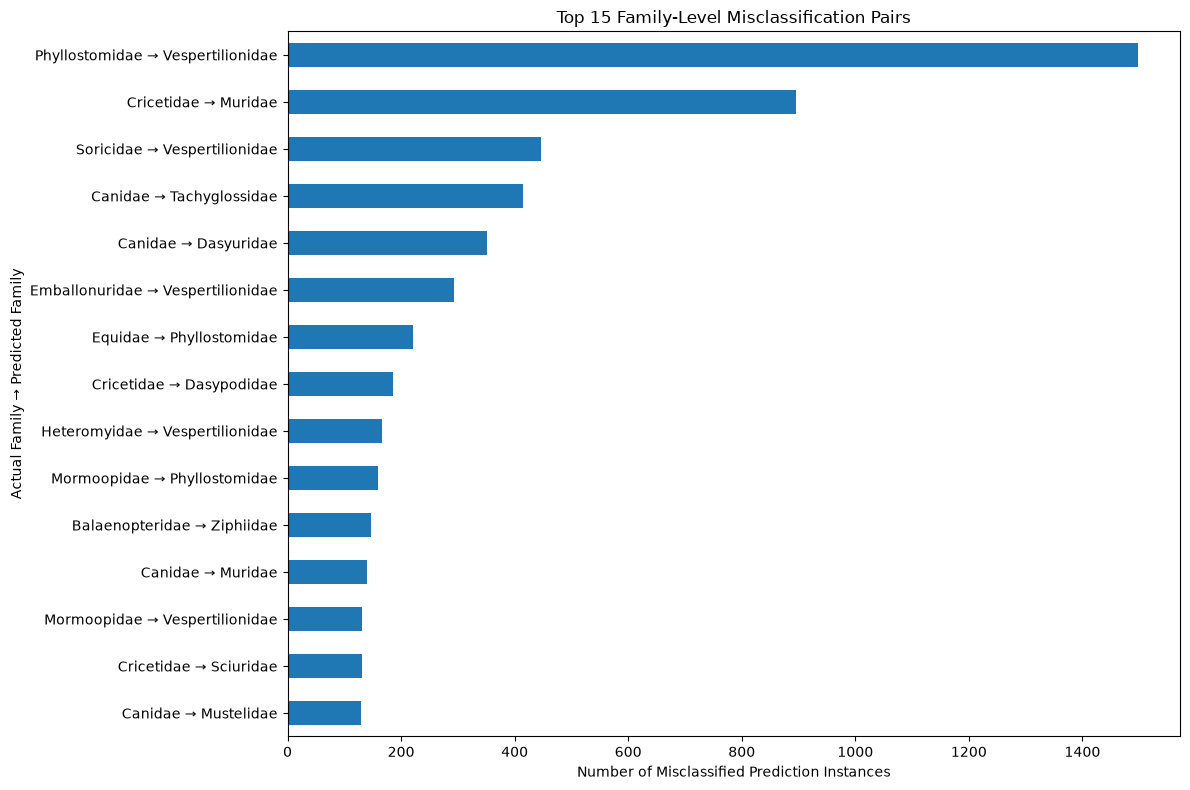


Section 18.5 results exported successfully.


In [45]:
# ============================================================
# SECTION 18.5 - COMMON MISCLASSIFICATION PATTERNS
# ============================================================

# ------------------------------------------------------------
# 1. Extract all misclassified prediction instances
# ------------------------------------------------------------

errors_df = predictions_df[
    predictions_df["correct"] == False
].copy()

print("Total misclassified prediction instances:", len(errors_df))


# ------------------------------------------------------------
# 2. Count actual-family -> predicted-family confusion pairs
# ------------------------------------------------------------

confusion_pairs = (
    errors_df
    .groupby(["actual_family", "predicted_family"])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("\nTOP 20 MOST FREQUENT FAMILY CONFUSION PAIRS")

display(confusion_pairs.head(20))


# ------------------------------------------------------------
# 3. Count confusion pairs separately for each experiment
# ------------------------------------------------------------

confusion_by_experiment = (
    errors_df
    .groupby([
        "validation",
        "model",
        "actual_family",
        "predicted_family"
    ])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("\nTOP 20 CONFUSION PAIRS ACROSS INDIVIDUAL EXPERIMENTS")

display(confusion_by_experiment.head(20))


# ------------------------------------------------------------
# 4. Identify pairs recurring across multiple models
# ------------------------------------------------------------

pair_model_recurrence = (
    confusion_by_experiment
    .groupby(["actual_family", "predicted_family"])
    .agg(
        total_errors=("error_count", "sum"),
        experiments_present=("model", "count"),
        models_present=("model", "nunique"),
        validation_categories=("validation", "nunique")
    )
    .reset_index()
    .sort_values(
        ["models_present", "total_errors"],
        ascending=False
    )
)

print("\nCONFUSION PAIRS RECURRING ACROSS MODELS")

display(pair_model_recurrence.head(20))


# ------------------------------------------------------------
# 5. Identify confusion pairs recurring across validations
# ------------------------------------------------------------

pair_validation_recurrence = (
    confusion_by_experiment
    .groupby(["actual_family", "predicted_family"])
    .agg(
        total_errors=("error_count", "sum"),
        models_present=("model", "nunique"),
        validation_categories=("validation", "nunique")
    )
    .reset_index()
    .sort_values(
        ["validation_categories", "total_errors"],
        ascending=False
    )
)

print("\nCONFUSION PAIRS RECURRING ACROSS VALIDATION STRATEGIES")

display(pair_validation_recurrence.head(20))


# ------------------------------------------------------------
# 6. Examine Linear SVM confusion pairs
# ------------------------------------------------------------

linear_svm_errors = errors_df[
    errors_df["model"] == "Linear SVM"
].copy()

linear_svm_confusions = (
    linear_svm_errors
    .groupby([
        "validation",
        "actual_family",
        "predicted_family"
    ])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("\nTOP 20 LINEAR SVM CONFUSION PAIRS")

display(linear_svm_confusions.head(20))


# ------------------------------------------------------------
# 7. Compare Linear SVM confusion pairs across validations
# ------------------------------------------------------------

linear_svm_confusion_comparison = (
    linear_svm_confusions
    .pivot_table(
        index=["actual_family", "predicted_family"],
        columns="validation",
        values="error_count",
        fill_value=0
    )
)

print("\nLINEAR SVM CONFUSION PAIR COMPARISON")

display(
    linear_svm_confusion_comparison
    .sort_values(
        by=list(linear_svm_confusion_comparison.columns),
        ascending=False
    )
    .head(30)
)


# ------------------------------------------------------------
# 8. Visualize the top 15 confusion pairs
# ------------------------------------------------------------

top_confusion_pairs = confusion_pairs.head(15).copy()

top_confusion_pairs["confusion_pair"] = (
    top_confusion_pairs["actual_family"]
    + " → "
    + top_confusion_pairs["predicted_family"]
)

plt.figure(figsize=(12, 8))

top_confusion_pairs.sort_values("error_count").plot(
    x="confusion_pair",
    y="error_count",
    kind="barh",
    legend=False,
    figsize=(12, 8)
)

plt.title("Top 15 Family-Level Misclassification Pairs")
plt.xlabel("Number of Misclassified Prediction Instances")
plt.ylabel("Actual Family → Predicted Family")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Export results
# ------------------------------------------------------------

confusion_pairs.to_csv(
    OUTPUT_DIR / "family_confusion_pairs_all_experiments.csv",
    index=False
)

confusion_by_experiment.to_csv(
    OUTPUT_DIR / "family_confusion_pairs_by_experiment.csv",
    index=False
)

pair_model_recurrence.to_csv(
    OUTPUT_DIR / "family_confusion_pair_model_recurrence.csv",
    index=False
)

pair_validation_recurrence.to_csv(
    OUTPUT_DIR / "family_confusion_pair_validation_recurrence.csv",
    index=False
)

linear_svm_confusions.to_csv(
    OUTPUT_DIR / "linear_svm_family_confusion_pairs.csv",
    index=False
)

linear_svm_confusion_comparison.to_csv(
    OUTPUT_DIR / "linear_svm_confusion_pair_comparison.csv"
)

print("\nSection 18.5 results exported successfully.")


## 18.6 Detailed Error Investigation of Linear SVM

This section investigates the classification errors made by Linear SVM, the best-performing model across the three validation strategies.

The analysis focuses on:
- Family-wise false negative and false positive counts.
- Family-wise false negative and false positive rates.
- The most frequent confusion pairs under each validation strategy.
- The proportion of each actual family's test records assigned to particular incorrect families.

The purpose is to understand the remaining weaknesses of the strongest model.

Total Linear SVM predictions: 24144
Total Linear SVM errors: 636

ERRORS BY VALIDATION STRATEGY


,validation,error_count
0,Validation A - Random,54
1,Validation B.1 - Duplicate Grouped,62
2,Validation B.2 - Species Grouped,520



LINEAR SVM FAMILY-WISE ERROR METRICS


,validation,family,actual_support,predicted_support,TP,FN,FP,precision,recall,F1,FN_rate_percentage,FP_rate_percentage
129,Validation A - Random,Acrobatidae,1,0,0,1,0,NaN,0.0,0.0,100.0,0.000000
131,Validation A - Random,Anomaluridae,1,0,0,1,0,NaN,0.0,0.0,100.0,0.000000
132,Validation A - Random,Antilocapridae,1,0,0,1,0,NaN,0.0,0.0,100.0,0.000000
150,Validation A - Random,Cheirogaleidae,1,0,0,1,0,NaN,0.0,0.0,100.0,0.000000
151,Validation A - Random,Chrysochloridae,1,1,0,1,1,0.0,0.0,0.0,100.0,0.014397
...,...,...,...,...,...,...,...,...,...,...,...,...
1511,Validation B.2 - Species Grouped,Vombatidae,1,1,1,0,0,1.0,1.0,1.0,0.0,0.000000
1439,Validation B.2 - Species Grouped,Eschrichtiidae,0,1,0,0,1,0.0,NaN,0.0,NaN,0.009939
1447,Validation B.2 - Species Grouped,Hippopotamidae,0,1,0,0,1,0.0,NaN,0.0,NaN,0.009939
1475,Validation B.2 - Species Grouped,Notoryctidae,0,1,0,0,1,0.0,NaN,0.0,NaN,0.009939



TOP 15 LINEAR SVM FALSE NEGATIVE FAMILIES PER VALIDATION

Validation A - Random


,family,actual_support,FN,FN_rate_percentage,recall
152,Cricetidae,878,8,0.911162,0.990888
252,Vespertilionidae,790,4,0.506329,0.994937
157,Dasypodidae,5,3,60.000000,0.400000
204,Muridae,569,3,0.527241,0.994728
235,Sciuridae,66,3,4.545455,0.954545
225,Phyllostomidae,1491,3,0.201207,0.997988
179,Heteromyidae,204,2,0.980392,0.990196
236,Soricidae,334,2,0.598802,0.994012
165,Echimyidae,100,2,2.000000,0.980000
131,Anomaluridae,1,1,100.000000,0.000000


... (20 outputs left out)


Validation B.2 - Species Grouped


,validation,actual_family,predicted_family,error_count,actual_support,pair_error_rate_percentage
125,Validation B.2 - Species Grouped,Macroscelididae,Cricetidae,5,5,100.000000
143,Validation B.2 - Species Grouped,Burramyidae,Sciuridae,2,2,100.000000
159,Validation B.2 - Species Grouped,Tragulidae,Bovidae,2,2,100.000000
162,Validation B.2 - Species Grouped,Acrobatidae,Hipposideridae,1,1,100.000000
166,Validation B.2 - Species Grouped,Cheirogaleidae,Erinaceidae,1,1,100.000000
167,Validation B.2 - Species Grouped,Chrysochloridae,Tapiridae,1,1,100.000000
181,Validation B.2 - Species Grouped,Giraffidae,Cricetidae,1,1,100.000000
182,Validation B.2 - Species Grouped,Gliridae,Heteromyidae,1,1,100.000000
197,Validation B.2 - Species Grouped,Peramelidae,Sciuridae,1,1,100.000000
198,Validation B.2 - Species Grouped,Petauridae,Geomyidae,1,1,100.000000



LINEAR SVM FAMILY-WISE FN RATE COMPARISON


validation,Validation A - Random,Validation B.1 - Duplicate Grouped,Validation B.2 - Species Grouped
family,,,
Acrobatidae,100.000000,100.000000,100.000000
Cheirogaleidae,100.000000,100.000000,100.000000
Chrysochloridae,100.000000,100.000000,100.000000
Petauridae,100.000000,100.000000,100.000000
Phalangeridae,100.000000,100.000000,100.000000
Tragulidae,100.000000,100.000000,100.000000
Anomaluridae,100.000000,100.000000,0.000000
Dugongidae,100.000000,100.000000,0.000000
Microbiotheriidae,100.000000,100.000000,0.000000


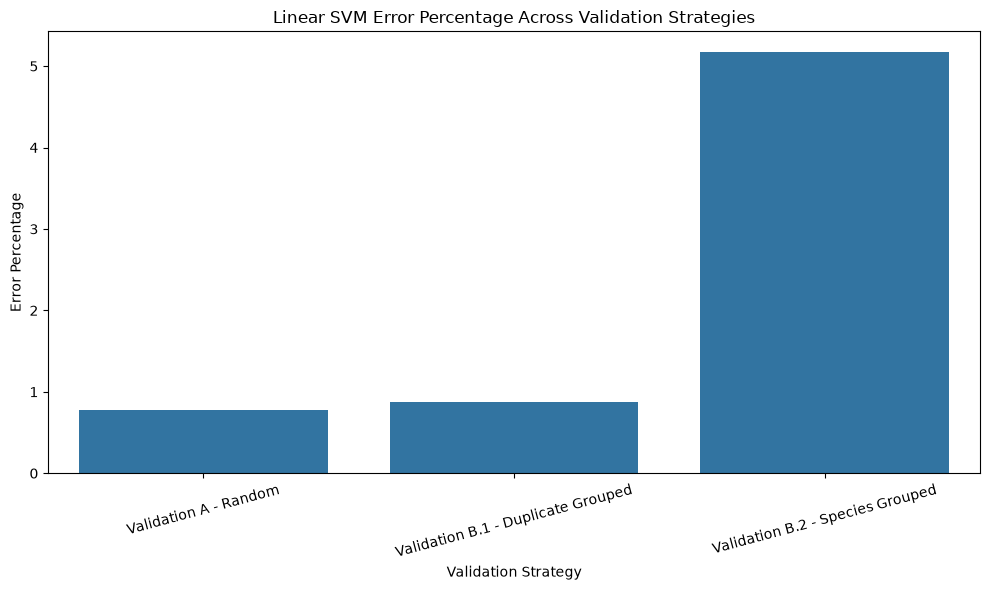

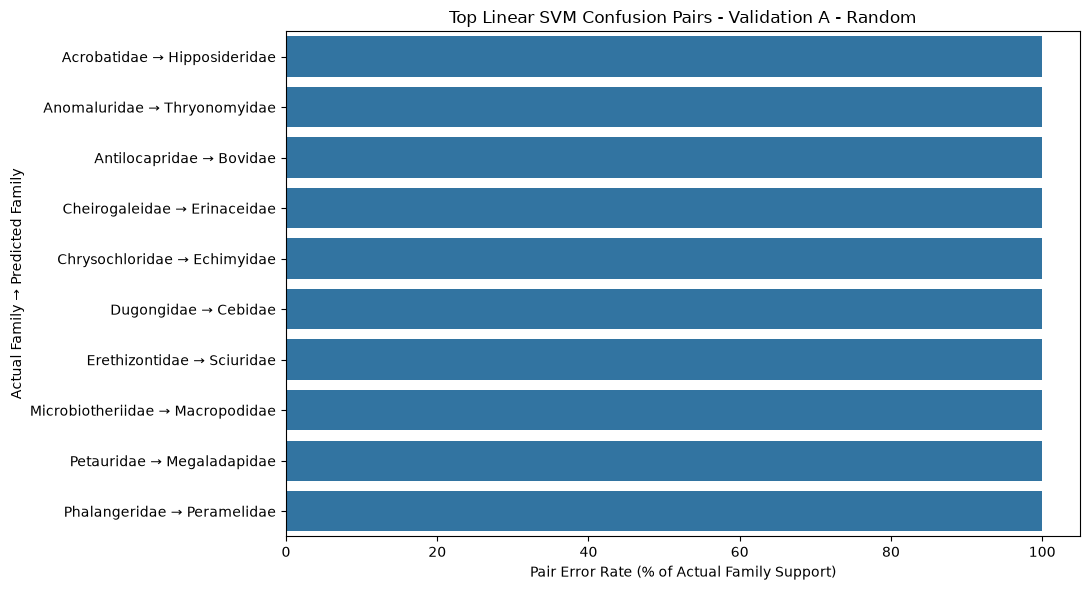

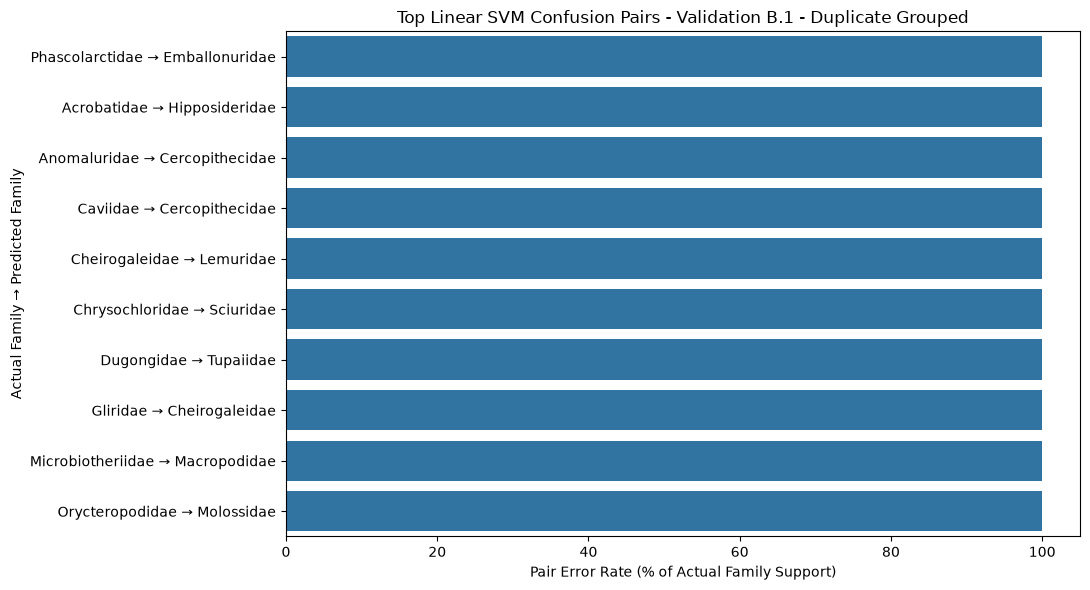

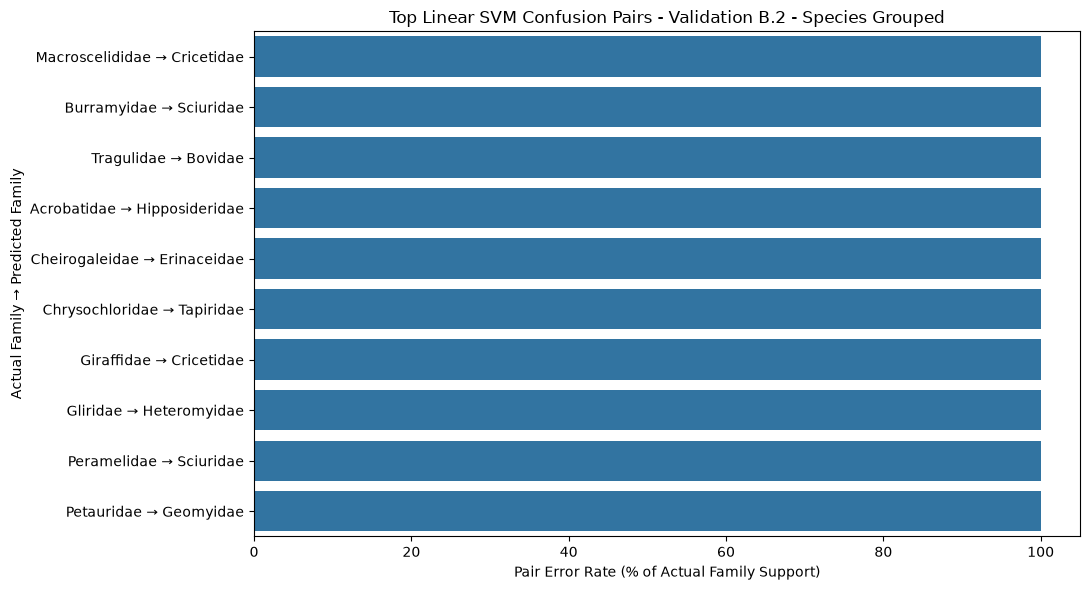


Section 18.6 results exported successfully.


In [ ]:
# ============================================================
# SECTION 18.6 - DETAILED LINEAR SVM ERROR INVESTIGATION
# ============================================================

# ------------------------------------------------------------
# 1. Extract Linear SVM predictions and errors
# ------------------------------------------------------------

linear_svm_predictions = predictions_df[
    predictions_df["model"] == "Linear SVM"
].copy()

linear_svm_errors = linear_svm_predictions[
    linear_svm_predictions["correct"] == False
].copy()

print("Total Linear SVM predictions:", len(linear_svm_predictions))
print("Total Linear SVM errors:", len(linear_svm_errors))

print("\nERRORS BY VALIDATION STRATEGY")

display(
    linear_svm_errors
    .groupby("validation")
    .size()
    .reset_index(name="error_count")
)


# ------------------------------------------------------------
# 2. Linear SVM family-wise FN and FP metrics
# ------------------------------------------------------------

linear_svm_family_metrics = family_metrics[
    family_metrics["model"] == "Linear SVM"
].copy()

linear_svm_family_metrics = linear_svm_family_metrics.sort_values(
    ["validation", "FN_rate_percentage"],
    ascending=[True, False]
)

print("\nLINEAR SVM FAMILY-WISE ERROR METRICS")

display(
    linear_svm_family_metrics[
        [
            "validation",
            "family",
            "actual_support",
            "predicted_support",
            "TP",
            "FN",
            "FP",
            "precision",
            "recall",
            "F1",
            "FN_rate_percentage",
            "FP_rate_percentage"
        ]
    ]
)


# ------------------------------------------------------------
# 3. Top 15 families with highest FN counts per validation
# ------------------------------------------------------------

print("\nTOP 15 LINEAR SVM FALSE NEGATIVE FAMILIES PER VALIDATION")

for validation_name in linear_svm_family_metrics["validation"].unique():

    print(f"\n{validation_name}")

    subset = (
        linear_svm_family_metrics[
            linear_svm_family_metrics["validation"] == validation_name
        ]
        .sort_values("FN", ascending=False)
        .head(15)
    )

    display(
        subset[
            [
                "family",
                "actual_support",
                "FN",
                "FN_rate_percentage",
                "recall"
            ]
        ]
    )


# ------------------------------------------------------------
# 4. Top 15 families with highest FP counts per validation
# ------------------------------------------------------------

print("\nTOP 15 LINEAR SVM FALSE POSITIVE FAMILIES PER VALIDATION")

for validation_name in linear_svm_family_metrics["validation"].unique():

    print(f"\n{validation_name}")

    subset = (
        linear_svm_family_metrics[
            linear_svm_family_metrics["validation"] == validation_name
        ]
        .sort_values("FP", ascending=False)
        .head(15)
    )

    display(
        subset[
            [
                "family",
                "predicted_support",
                "FP",
                "FP_rate_percentage",
                "precision"
            ]
        ]
    )


# ------------------------------------------------------------
# 5. Find the most frequent confusion pairs per validation
# ------------------------------------------------------------

linear_svm_confusions_by_validation = (
    linear_svm_errors
    .groupby([
        "validation",
        "actual_family",
        "predicted_family"
    ])
    .size()
    .reset_index(name="error_count")
    .sort_values(
        ["validation", "error_count"],
        ascending=[True, False]
    )
)

print("\nTOP 15 CONFUSION PAIRS PER VALIDATION")

for validation_name in linear_svm_confusions_by_validation["validation"].unique():

    print(f"\n{validation_name}")

    display(
        linear_svm_confusions_by_validation[
            linear_svm_confusions_by_validation["validation"]
            == validation_name
        ].head(15)
    )


# ------------------------------------------------------------
# 6. Calculate confusion-pair rates
# ------------------------------------------------------------
# For each actual family:
# confusion_pair_rate = errors to one predicted family
#                       / total test records of actual family
#
# This helps compare pairs without relying only on raw counts.

linear_svm_actual_support = (
    linear_svm_predictions
    .groupby(["validation", "actual_family"])
    .size()
    .reset_index(name="actual_support")
)

linear_svm_pair_rates = linear_svm_confusions_by_validation.merge(
    linear_svm_actual_support,
    on=["validation", "actual_family"],
    how="left"
)

linear_svm_pair_rates["pair_error_rate_percentage"] = (
    linear_svm_pair_rates["error_count"]
    / linear_svm_pair_rates["actual_support"]
) * 100

linear_svm_pair_rates = linear_svm_pair_rates.sort_values(
    ["validation", "pair_error_rate_percentage"],
    ascending=[True, False]
)

print("\nTOP CONFUSION PAIRS BY RATE PER VALIDATION")

for validation_name in linear_svm_pair_rates["validation"].unique():

    print(f"\n{validation_name}")

    display(
        linear_svm_pair_rates[
            linear_svm_pair_rates["validation"] == validation_name
        ].head(15)
    )


# ------------------------------------------------------------
# 7. Compare Linear SVM error rates across validations
# ------------------------------------------------------------

linear_svm_error_rate_comparison = (
    linear_svm_family_metrics
    .pivot_table(
        index="family",
        columns="validation",
        values="FN_rate_percentage",
        fill_value=0
    )
)

print("\nLINEAR SVM FAMILY-WISE FN RATE COMPARISON")

display(
    linear_svm_error_rate_comparison
    .sort_values(
        by=list(linear_svm_error_rate_comparison.columns),
        ascending=False
    )
    .head(30)
)


# ------------------------------------------------------------
# 8. Visualize Linear SVM error counts by validation
# ------------------------------------------------------------

linear_svm_error_plot = (
    linear_svm_predictions
    .groupby("validation")
    .agg(
        total_predictions=("correct", "size"),
        errors=("correct", lambda x: (~x).sum())
    )
)

linear_svm_error_plot["error_percentage"] = (
    linear_svm_error_plot["errors"]
    / linear_svm_error_plot["total_predictions"]
) * 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=linear_svm_error_plot.reset_index(),
    x="validation",
    y="error_percentage"
)

plt.title("Linear SVM Error Percentage Across Validation Strategies")
plt.xlabel("Validation Strategy")
plt.ylabel("Error Percentage")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Visualize top confusion pairs for each validation
# ------------------------------------------------------------

for validation_name in linear_svm_pair_rates["validation"].unique():

    plot_data = (
        linear_svm_pair_rates[
            linear_svm_pair_rates["validation"] == validation_name
        ]
        .head(10)
        .copy()
    )

    plot_data["confusion_pair"] = (
        plot_data["actual_family"]
        + " → "
        + plot_data["predicted_family"]
    )

    plt.figure(figsize=(11, 6))

    sns.barplot(
        data=plot_data,
        x="pair_error_rate_percentage",
        y="confusion_pair"
    )

    plt.title(f"Top Linear SVM Confusion Pairs - {validation_name}")
    plt.xlabel("Pair Error Rate (% of Actual Family Support)")
    plt.ylabel("Actual Family → Predicted Family")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 10. Export all Linear SVM investigation results
# ------------------------------------------------------------

linear_svm_family_metrics.to_csv(
    OUTPUT_DIR / "linear_svm_family_wise_error_metrics.csv",
    index=False
)

linear_svm_confusions_by_validation.to_csv(
    OUTPUT_DIR / "linear_svm_confusions_by_validation.csv",
    index=False
)

linear_svm_pair_rates.to_csv(
    OUTPUT_DIR / "linear_svm_confusion_pair_rates.csv",
    index=False
)

linear_svm_error_rate_comparison.to_csv(
    OUTPUT_DIR / "linear_svm_fn_rate_comparison.csv"
)

linear_svm_error_plot.to_csv(
    OUTPUT_DIR / "linear_svm_error_rate_summary.csv"
)

print("\nSection 18.6 results exported successfully.")


## 18.7 Investigating the Effect of Sequence Characteristics

This section examines whether sequence characteristics are associated with classification performance.

The analysis considers:
- Sequence length.
- Ambiguous nucleotide count, where available.
- GC content.
- Differences between correctly and incorrectly classified records.
- Differences across validation strategies.

The purpose is to identify possible associations between sequence characteristics and classification errors. These associations do not establish causation.

In [ ]:
# ============================================================
# SECTION 18.7 - SEQUENCE CHARACTERISTICS AND ERRORS
# ============================================================

# Use Linear SVM as the primary model for this investigation.

svm_sequence_df = linear_svm_predictions.copy()

# Retrieve sequence information from model_records.
# processid is used to connect prediction records with source records.

sequence_metadata_columns = [
    "processid",
    "sequence",
    "sequence_length",
    "ambiguous_base_count"
]

available_columns = [
    col for col in sequence_metadata_columns
    if col in model_records.columns
]

sequence_metadata = model_records[available_columns].copy()

# Remove duplicate process IDs from the metadata lookup.
# Keep the first occurrence to avoid multiplying prediction rows.
sequence_metadata = sequence_metadata.drop_duplicates(
    subset=["processid"]
)

# Merge sequence information into predictions.
svm_sequence_df = svm_sequence_df.merge(
    sequence_metadata,
    on="processid",
    how="left",
    suffixes=("", "_source")
)

print("Linear SVM prediction records:", len(svm_sequence_df))

print("\nMissing sequence values:")
display(svm_sequence_df["sequence"].isna().sum())


Linear SVM prediction records: 24144

Missing sequence values:


np.int64(0)

In [ ]:
# ------------------------------------------------------------
# Calculate GC content
# ------------------------------------------------------------

def calculate_gc_content(sequence):

    if pd.isna(sequence):
        return np.nan

    sequence = str(sequence).upper()

    valid_bases = [
        base for base in sequence
        if base in "ACGT"
    ]

    if len(valid_bases) == 0:
        return np.nan

    gc_count = valid_bases.count("G") + valid_bases.count("C")

    return (gc_count / len(valid_bases)) * 100


svm_sequence_df["gc_content"] = (
    svm_sequence_df["sequence"]
    .apply(calculate_gc_content)
)

print("GC content calculated.")

display(
    svm_sequence_df[
        [
            "processid",
            "actual_family",
            "predicted_family",
            "correct",
            "sequence_length",
            "ambiguous_base_count",
            "gc_content"
        ]
    ].head(10)
)


GC content calculated.


,processid,actual_family,predicted_family,correct,sequence_length,ambiguous_base_count,gc_content
0,BCBNT885-06,Phyllostomidae,Phyllostomidae,True,657,0,40.334855
1,GBMIN43168-14,Delphinidae,Delphinidae,True,1548,0,39.793282
2,ABGYC477-06,Phyllostomidae,Phyllostomidae,True,657,0,43.835616
3,ABGYG1105-08,Phyllostomidae,Phyllostomidae,True,657,0,40.334855
4,ABBWP279-07,Vespertilionidae,Vespertilionidae,True,657,0,41.856925
5,ABGYD221-06,Phyllostomidae,Phyllostomidae,True,657,0,44.596651
6,ABECB097-08,Echimyidae,Echimyidae,True,657,0,38.356164
7,GBMA16835-17,Muridae,Muridae,True,690,0,39.855072
8,GBMIN42145-14,Vespertilionidae,Vespertilionidae,True,513,0,40.155945
9,GBMTG5607-16,Felidae,Felidae,True,1542,0,41.050584


In [ ]:
# ------------------------------------------------------------
# Compare sequence characteristics by prediction correctness
# ------------------------------------------------------------

characteristics = [
    col for col in [
        "sequence_length",
        "ambiguous_base_count",
        "gc_content"
    ]
    if col in svm_sequence_df.columns
]

characteristics_summary = (
    svm_sequence_df
    .groupby("correct")[characteristics]
    .agg(["count", "mean", "median", "std"])
)

print("SEQUENCE CHARACTERISTICS: CORRECT VS INCORRECT")

display(characteristics_summary)


SEQUENCE CHARACTERISTICS: CORRECT VS INCORRECT


sequence_length                                ambiguous_base_count  \
                  count        mean median         std                count   
correct                                                                       
False               636  828.262579  657.0  359.689002                  636   
True              23508  752.676493  657.0  260.403509                23508   

                         gc_content                                  
        mean median  std      count       mean     median       std  
correct                                                              
False    0.0    0.0  0.0        636  42.452191  41.855691  3.146787  
True     0.0    0.0  0.0      23508  42.560678  42.161339  2.598661

In [ ]:
# ------------------------------------------------------------
# Group records by sequence length
# ------------------------------------------------------------

svm_sequence_df["sequence_length_group"] = pd.cut(
    svm_sequence_df["sequence_length"],
    bins=[0, 300, 400, 500, 600, 700, np.inf],
    labels=[
        "Below 300",
        "300-400",
        "400-500",
        "500-600",
        "600-700",
        "Above 700"
    ],
    right=False
)

length_error_summary = (
    svm_sequence_df
    .groupby("sequence_length_group", observed=False)
    .agg(
        total_records=("correct", "size"),
        errors=("correct", lambda x: (~x).sum())
    )
    .reset_index()
)

length_error_summary["error_percentage"] = (
    length_error_summary["errors"]
    / length_error_summary["total_records"]
) * 100

print("ERROR RATE BY SEQUENCE LENGTH")

display(length_error_summary)


ERROR RATE BY SEQUENCE LENGTH


,sequence_length_group,total_records,errors,error_percentage
0,Below 300,36,5,13.888889
1,300-400,46,4,8.695652
2,400-500,303,38,12.541254
3,500-600,1224,17,1.388889
4,600-700,17355,384,2.212619
5,Above 700,5180,188,3.629344


In [ ]:
# ------------------------------------------------------------
# Group records by GC content
# ------------------------------------------------------------

svm_sequence_df["gc_content_group"] = pd.cut(
    svm_sequence_df["gc_content"],
    bins=[0, 30, 40, 50, 60, 70, 100],
    labels=[
        "Below 30%",
        "30-40%",
        "40-50%",
        "50-60%",
        "60-70%",
        "Above 70%"
    ],
    include_lowest=True
)

gc_error_summary = (
    svm_sequence_df
    .groupby("gc_content_group", observed=False)
    .agg(
        total_records=("correct", "size"),
        errors=("correct", lambda x: (~x).sum())
    )
    .reset_index()
)

gc_error_summary["error_percentage"] = (
    gc_error_summary["errors"]
    / gc_error_summary["total_records"]
) * 100

print("ERROR RATE BY GC CONTENT")

display(gc_error_summary)


ERROR RATE BY GC CONTENT


,gc_content_group,total_records,errors,error_percentage
0,Below 30%,0,0,NaN
1,30-40%,3350,126,3.761194
2,40-50%,20538,489,2.380952
3,50-60%,256,21,8.203125
4,60-70%,0,0,NaN
5,Above 70%,0,0,NaN


In [ ]:
# ------------------------------------------------------------
# Sequence characteristics by validation strategy
# ------------------------------------------------------------

validation_characteristics = (
    svm_sequence_df
    .groupby("validation")
    .agg(
        total_records=("correct", "size"),
        errors=("correct", lambda x: (~x).sum()),
        average_sequence_length=("sequence_length", "mean"),
        median_sequence_length=("sequence_length", "median"),
        average_gc_content=("gc_content", "mean"),
        median_gc_content=("gc_content", "median")
    )
    .reset_index()
)

validation_characteristics["error_percentage"] = (
    validation_characteristics["errors"]
    / validation_characteristics["total_records"]
) * 100

print("VALIDATION-WISE SEQUENCE CHARACTERISTICS")

display(validation_characteristics)


VALIDATION-WISE SEQUENCE CHARACTERISTICS


,validation,total_records,errors,average_sequence_length,median_sequence_length,average_gc_content,median_gc_content,error_percentage
0,Validation A - Random,6947,54,738.098316,657.0,42.601953,42.161339,0.777314
1,Validation B.1 - Duplicate Grouped,7136,62,738.709641,657.0,42.568668,42.161339,0.868834
2,Validation B.2 - Species Grouped,10061,520,777.426995,657.0,42.519653,42.161339,5.168472


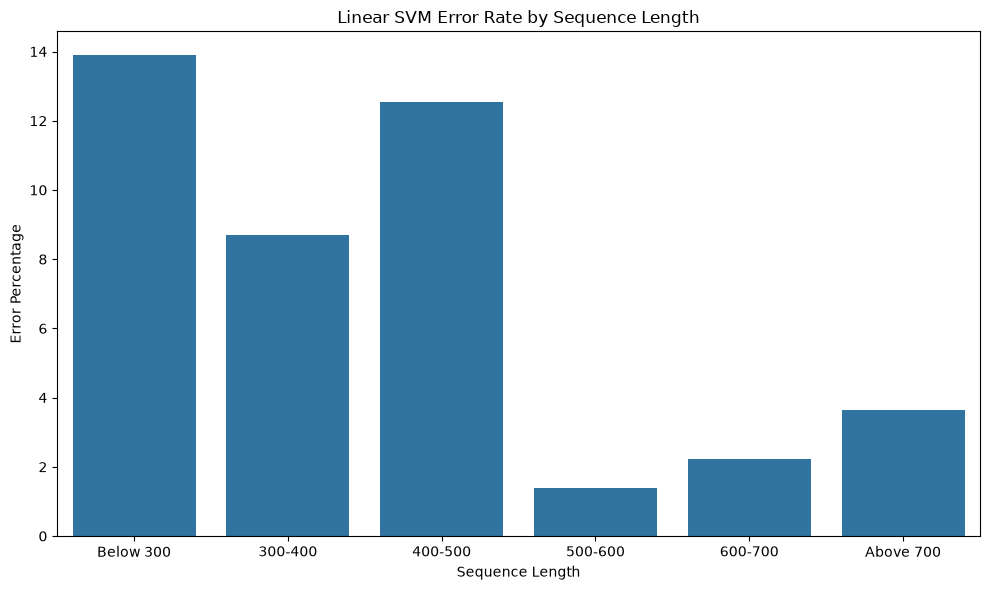

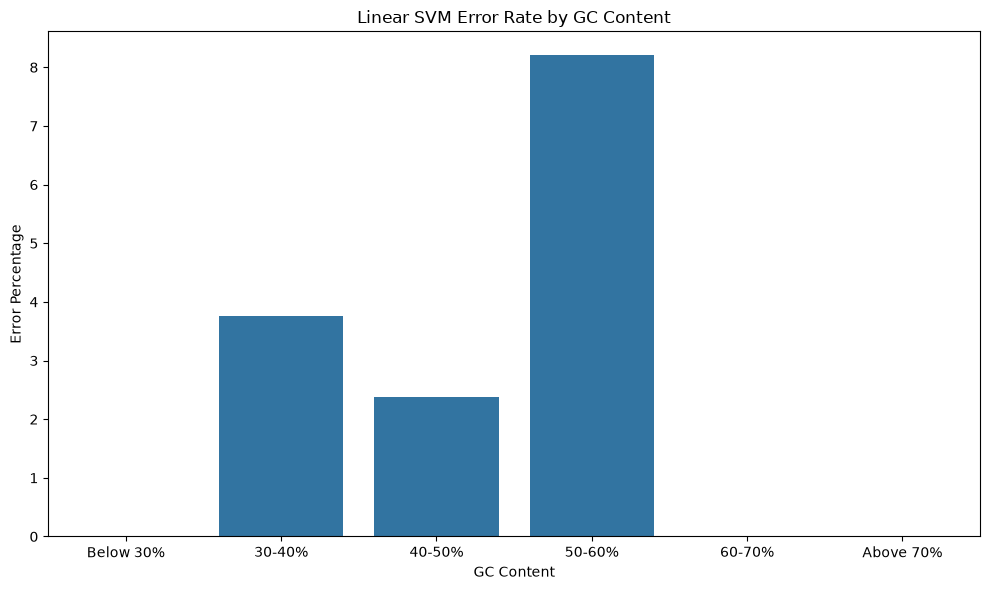

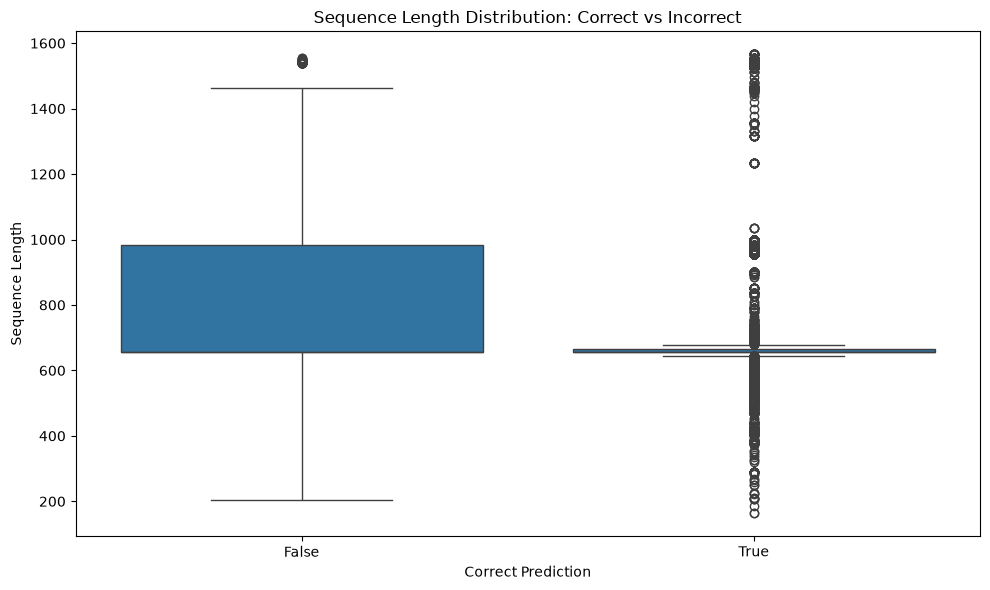

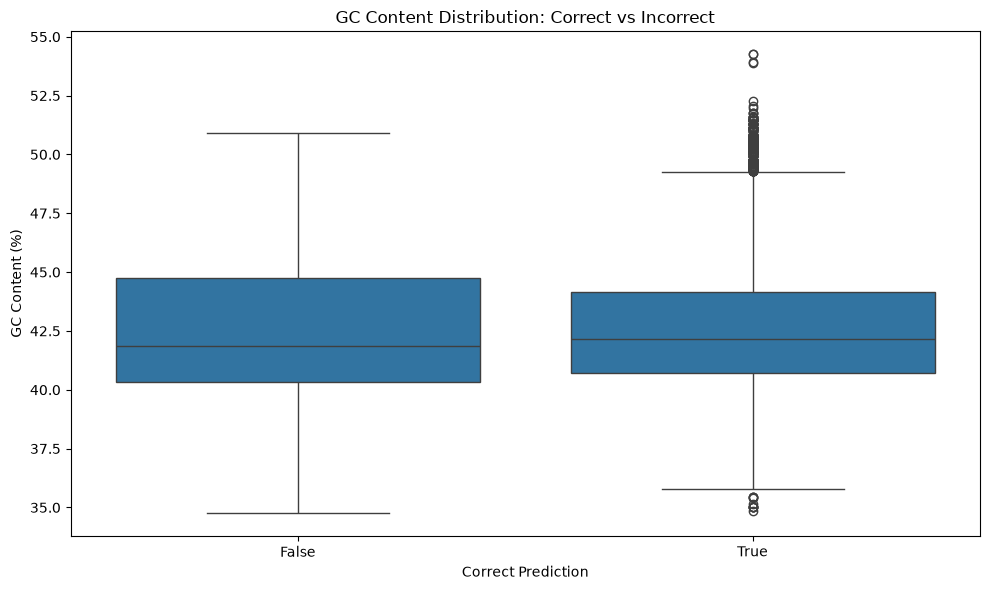

In [ ]:
# ------------------------------------------------------------
# Error percentage by sequence length
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=length_error_summary,
    x="sequence_length_group",
    y="error_percentage"
)

plt.title("Linear SVM Error Rate by Sequence Length")
plt.xlabel("Sequence Length")
plt.ylabel("Error Percentage")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Error percentage by GC content
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.barplot(
    data=gc_error_summary,
    x="gc_content_group",
    y="error_percentage"
)

plt.title("Linear SVM Error Rate by GC Content")
plt.xlabel("GC Content")
plt.ylabel("Error Percentage")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sequence length distribution: correct vs incorrect
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=svm_sequence_df,
    x="correct",
    y="sequence_length"
)

plt.title("Sequence Length Distribution: Correct vs Incorrect")
plt.xlabel("Correct Prediction")
plt.ylabel("Sequence Length")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GC content distribution: correct vs incorrect
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=svm_sequence_df,
    x="correct",
    y="gc_content"
)

plt.title("GC Content Distribution: Correct vs Incorrect")
plt.xlabel("Correct Prediction")
plt.ylabel("GC Content (%)")
plt.tight_layout()
plt.show()


In [ ]:
# ------------------------------------------------------------
# Export Section 18.7 results
# ------------------------------------------------------------

characteristics_summary.to_csv(
    OUTPUT_DIR / "linear_svm_sequence_characteristics_correct_vs_incorrect.csv"
)

length_error_summary.to_csv(
    OUTPUT_DIR / "linear_svm_error_by_sequence_length.csv",
    index=False
)

gc_error_summary.to_csv(
    OUTPUT_DIR / "linear_svm_error_by_gc_content.csv",
    index=False
)

validation_characteristics.to_csv(
    OUTPUT_DIR / "linear_svm_validation_sequence_characteristics.csv",
    index=False
)

print("Section 18.7 results exported successfully.")


Section 18.7 results exported successfully.


## 18.8 Statistical Analysis of Error Patterns

This section statistically investigates the relationship between DNA sequence characteristics and Linear SVM classification errors.

The analysis includes:

- Mann–Whitney U tests to compare sequence length and GC content between correctly and incorrectly classified records.
- Chi-square tests to examine associations between grouped sequence characteristics and prediction correctness.
- Effect sizes to assess the magnitude of observed differences.
- Bonferroni correction to account for multiple statistical tests.

All tests are performed separately for the three validation strategies to avoid pooling repeated prediction results.

The results indicate statistical associations, not causal relationships.

In [ ]:
# ============================================================
# SECTION 18.8 - STATISTICAL ANALYSIS OF ERROR PATTERNS
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import mannwhitneyu, chi2_contingency

# Use the existing Linear SVM sequence-level dataset.
stats_df = svm_sequence_df.copy()

# Remove records without the required measurements.
stats_df = stats_df.dropna(
    subset=[
        "sequence_length",
        "gc_content",
        "correct",
        "validation"
    ]
).copy()

# Ensure correct data types.
stats_df["sequence_length"] = pd.to_numeric(
    stats_df["sequence_length"],
    errors="coerce"
)

stats_df["gc_content"] = pd.to_numeric(
    stats_df["gc_content"],
    errors="coerce"
)

stats_df = stats_df.dropna(
    subset=["sequence_length", "gc_content"]
)

stats_df["correct"] = stats_df["correct"].astype(bool)

print("Records available for statistical analysis:", len(stats_df))

print("\nRecords by validation strategy:")

display(
    stats_df.groupby("validation").agg(
        total_records=("correct", "size"),
        correct_predictions=("correct", "sum"),
        incorrect_predictions=("correct", lambda x: (~x).sum())
    )
)


Records available for statistical analysis: 24144

Records by validation strategy:


,total_records,correct_predictions,incorrect_predictions
validation,,,
Validation A - Random,6947,6893,54
Validation B.1 - Duplicate Grouped,7136,7074,62
Validation B.2 - Species Grouped,10061,9541,520


In [ ]:
# ------------------------------------------------------------
# Create broader sequence-length groups
# ------------------------------------------------------------

stats_df["sequence_length_group"] = pd.cut(
    stats_df["sequence_length"],
    bins=[0, 500, 700, np.inf],
    labels=[
        "Below 500",
        "500-700",
        "Above 700"
    ],
    right=False
)

# ------------------------------------------------------------
# Create broader GC-content groups
# ------------------------------------------------------------

stats_df["gc_content_group"] = pd.cut(
    stats_df["gc_content"],
    bins=[0, 40, 50, 100.0001],
    labels=[
        "Below 40%",
        "40-50%",
        "Above 50%"
    ],
    right=True,
    include_lowest=True
)

print("Sequence length group distribution:")

display(
    stats_df["sequence_length_group"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nGC content group distribution:")

display(
    stats_df["gc_content_group"]
    .value_counts(dropna=False)
    .sort_index()
)


Sequence length group distribution:


sequence_length_group
Below 500      385
500-700      18579
Above 700     5180
Name: count, dtype: int64


GC content group distribution:


gc_content_group
Below 40%     3350
40-50%       20538
Above 50%      256
Name: count, dtype: int64

In [ ]:
# ------------------------------------------------------------
# Mann-Whitney U test and Cliff's delta
# ------------------------------------------------------------

def calculate_cliffs_delta(incorrect_values, correct_values):

    n1 = len(incorrect_values)
    n2 = len(correct_values)

    if n1 == 0 or n2 == 0:
        return np.nan

    result = mannwhitneyu(
        incorrect_values,
        correct_values,
        alternative="two-sided"
    )

    # U corresponds to the first sample: incorrect records.
    cliffs_delta = (2 * result.statistic / (n1 * n2)) - 1

    return cliffs_delta


mann_whitney_results = []

for validation_name in stats_df["validation"].unique():

    validation_data = stats_df[
        stats_df["validation"] == validation_name
    ]

    incorrect = validation_data[
        validation_data["correct"] == False
    ]

    correct = validation_data[
        validation_data["correct"] == True
    ]

    for characteristic in [
        "sequence_length",
        "gc_content"
    ]:

        incorrect_values = incorrect[characteristic].dropna()
        correct_values = correct[characteristic].dropna()

        if len(incorrect_values) == 0 or len(correct_values) == 0:
            continue

        test_result = mannwhitneyu(
            incorrect_values,
            correct_values,
            alternative="two-sided"
        )

        cliffs_delta = calculate_cliffs_delta(
            incorrect_values,
            correct_values
        )

        mann_whitney_results.append({

            "validation": validation_name,
            "characteristic": characteristic,

            "incorrect_count": len(incorrect_values),
            "correct_count": len(correct_values),

            "incorrect_median": incorrect_values.median(),
            "correct_median": correct_values.median(),

            "incorrect_mean": incorrect_values.mean(),
            "correct_mean": correct_values.mean(),

            "U_statistic": test_result.statistic,
            "p_value": test_result.pvalue,

            "cliffs_delta": cliffs_delta
        })


mann_whitney_df = pd.DataFrame(mann_whitney_results)

print("MANN-WHITNEY U TEST RESULTS")

display(mann_whitney_df)


MANN-WHITNEY U TEST RESULTS


,validation,characteristic,incorrect_count,correct_count,incorrect_median,correct_median,incorrect_mean,correct_mean,U_statistic,p_value,cliffs_delta
0,Validation A - Random,sequence_length,54,6893,1539.000000,657.000000,1129.851852,735.029305,254048.5,3.818471e-07,0.365038
1,Validation A - Random,gc_content,54,6893,40.531777,42.161339,41.037341,42.614210,126134.0,4.395511e-05,-0.322265
2,Validation B.1 - Duplicate Grouped,sequence_length,62,7074,658.000000,657.000000,974.887097,736.639666,269354.5,6.967436e-04,0.228280
3,Validation B.1 - Duplicate Grouped,gc_content,62,7074,42.617960,42.157194,43.364858,42.561690,232457.0,4.150588e-01,0.060024
4,Validation B.2 - Species Grouped,sequence_length,520,9541,657.000000,657.000000,779.461538,777.316109,2354357.5,3.838839e-02,-0.050915
5,Validation B.2 - Species Grouped,gc_content,520,9541,41.901776,42.165242,42.490300,42.521253,2411461.5,2.833187e-01,-0.027895


In [ ]:
# ------------------------------------------------------------
# Chi-square tests and Cramer's V
# ------------------------------------------------------------

chi_square_results = []

for validation_name in stats_df["validation"].unique():

    validation_data = stats_df[
        stats_df["validation"] == validation_name
    ]

    for characteristic_group in [
        "sequence_length_group",
        "gc_content_group"
    ]:

        contingency_table = pd.crosstab(
            validation_data[characteristic_group],
            validation_data["correct"]
        )

        # Remove categories with no observations.
        contingency_table = contingency_table.loc[
            contingency_table.sum(axis=1) > 0,
            :
        ]

        if (
            contingency_table.shape[0] < 2
            or contingency_table.shape[1] < 2
        ):
            continue

        chi2, p_value, degrees_of_freedom, expected = (
            chi2_contingency(contingency_table)
        )

        total_observations = contingency_table.to_numpy().sum()

        minimum_dimension = min(
            contingency_table.shape[0] - 1,
            contingency_table.shape[1] - 1
        )

        cramers_v = np.sqrt(
            chi2 / (total_observations * minimum_dimension)
        )

        minimum_expected_frequency = expected.min()

        chi_square_results.append({

            "validation": validation_name,
            "characteristic": characteristic_group,

            "chi_square_statistic": chi2,
            "degrees_of_freedom": degrees_of_freedom,
            "p_value": p_value,

            "cramers_v": cramers_v,

            "minimum_expected_frequency": minimum_expected_frequency,

            "expected_frequency_below_5": (
                expected < 5
            ).sum()
        })


chi_square_df = pd.DataFrame(chi_square_results)

print("CHI-SQUARE TEST RESULTS")

display(chi_square_df)


CHI-SQUARE TEST RESULTS


,validation,characteristic,chi_square_statistic,degrees_of_freedom,p_value,cramers_v,minimum_expected_frequency,expected_frequency_below_5
0,Validation A - Random,sequence_length_group,93.930144,2,4.011699e-21,0.116280,0.893911,1
1,Validation A - Random,gc_content_group,52.141995,2,4.758933e-12,0.086635,0.722902,1
2,Validation B.1 - Duplicate Grouped,sequence_length_group,30.093690,2,2.919028e-07,0.064940,0.999159,1
3,Validation B.1 - Duplicate Grouped,gc_content_group,107.434690,2,4.686554e-24,0.122700,0.712444,1
4,Validation B.2 - Species Grouped,sequence_length_group,120.339676,2,7.388757e-27,0.109366,8.011132,0
5,Validation B.2 - Species Grouped,gc_content_group,17.963551,2,1.256795e-04,0.042255,4.186463,1


In [ ]:
# ------------------------------------------------------------
# Combine p-values and apply Bonferroni correction
# ------------------------------------------------------------

mann_whitney_df["test_type"] = "Mann-Whitney U"

chi_square_df["test_type"] = "Chi-square"

mann_whitney_df["test_name"] = (
    mann_whitney_df["characteristic"]
)

chi_square_df["test_name"] = (
    chi_square_df["characteristic"]
)

statistical_results = pd.concat(
    [
        mann_whitney_df[
            [
                "validation",
                "test_type",
                "test_name",
                "p_value"
            ]
        ],

        chi_square_df[
            [
                "validation",
                "test_type",
                "test_name",
                "p_value"
            ]
        ]
    ],
    ignore_index=True
)

number_of_tests = len(statistical_results)

statistical_results["bonferroni_p_value"] = np.minimum(
    statistical_results["p_value"] * number_of_tests,
    1.0
)

statistical_results["significant_before_correction"] = (
    statistical_results["p_value"] < 0.05
)

statistical_results["significant_after_correction"] = (
    statistical_results["bonferroni_p_value"] < 0.05
)

print("NUMBER OF STATISTICAL TESTS:", number_of_tests)

print("\nSTATISTICAL SIGNIFICANCE RESULTS")

display(
    statistical_results.sort_values(
        "bonferroni_p_value"
    )
)


NUMBER OF STATISTICAL TESTS: 12

STATISTICAL SIGNIFICANCE RESULTS


,validation,test_type,test_name,p_value,bonferroni_p_value,significant_before_correction,significant_after_correction
10,Validation B.2 - Species Grouped,Chi-square,sequence_length_group,7.388757e-27,8.866508e-26,True,True
9,Validation B.1 - Duplicate Grouped,Chi-square,gc_content_group,4.686554e-24,5.623864e-23,True,True
6,Validation A - Random,Chi-square,sequence_length_group,4.011699e-21,4.814038e-20,True,True
7,Validation A - Random,Chi-square,gc_content_group,4.758933e-12,5.710720e-11,True,True
8,Validation B.1 - Duplicate Grouped,Chi-square,sequence_length_group,2.919028e-07,3.502834e-06,True,True
0,Validation A - Random,Mann-Whitney U,sequence_length,3.818471e-07,4.582165e-06,True,True
1,Validation A - Random,Mann-Whitney U,gc_content,4.395511e-05,5.274613e-04,True,True
11,Validation B.2 - Species Grouped,Chi-square,gc_content_group,1.256795e-04,1.508154e-03,True,True
2,Validation B.1 - Duplicate Grouped,Mann-Whitney U,sequence_length,6.967436e-04,8.360924e-03,True,True
4,Validation B.2 - Species Grouped,Mann-Whitney U,sequence_length,3.838839e-02,4.606607e-01,True,False


In [ ]:
# ------------------------------------------------------------
# Display contingency tables for each validation
# ------------------------------------------------------------

for validation_name in stats_df["validation"].unique():

    validation_data = stats_df[
        stats_df["validation"] == validation_name
    ]

    print("\n" + "=" * 70)
    print(validation_name)
    print("=" * 70)

    print("\nSequence Length Group vs Prediction Correctness")

    display(
        pd.crosstab(
            validation_data["sequence_length_group"],
            validation_data["correct"],
            margins=True
        )
    )

    print("\nGC Content Group vs Prediction Correctness")

    display(
        pd.crosstab(
            validation_data["gc_content_group"],
            validation_data["correct"],
            margins=True
        )
    )



Validation A - Random

Sequence Length Group vs Prediction Correctness


correct,False,True,All
sequence_length_group,,,
Below 500,5,110,115
500-700,16,5580,5596
Above 700,33,1203,1236
All,54,6893,6947



GC Content Group vs Prediction Correctness


correct,False,True,All
gc_content_group,,,
Below 40%,26,956,982
40-50%,28,5844,5872
Above 50%,0,93,93
All,54,6893,6947



Validation B.1 - Duplicate Grouped

Sequence Length Group vs Prediction Correctness


correct,False,True,All
sequence_length_group,,,
Below 500,4,111,115
500-700,33,5650,5683
Above 700,25,1313,1338
All,62,7074,7136


... (2 outputs left out)


Validation B.2 - Species Grouped

Sequence Length Group vs Prediction Correctness


correct,False,True,All
sequence_length_group,,,
Below 500,38,117,155
500-700,352,6948,7300
Above 700,130,2476,2606
All,520,9541,10061



GC Content Group vs Prediction Correctness


correct,False,True,All
gc_content_group,,,
Below 40%,85,1346,1431
40-50%,423,8126,8549
Above 50%,12,69,81
All,520,9541,10061


In [ ]:
# ------------------------------------------------------------
# Export statistical analysis results
# ------------------------------------------------------------

mann_whitney_df.to_csv(
    OUTPUT_DIR / "linear_svm_mann_whitney_tests.csv",
    index=False
)

chi_square_df.to_csv(
    OUTPUT_DIR / "linear_svm_chi_square_tests.csv",
    index=False
)

statistical_results.to_csv(
    OUTPUT_DIR / "linear_svm_statistical_significance_summary.csv",
    index=False
)

print("Section 18.8 statistical analysis completed.")
print("All results exported successfully.")


Section 18.8 statistical analysis completed.
All results exported successfully.


## 18.9 Robust Statistical Validation

This section reassesses the statistical associations identified in Section 18.8.

The analysis includes:

- Monte Carlo chi-square tests for contingency tables with low expected frequencies.
- Comparison of asymptotic and Monte Carlo p-values.
- Recalculation of Cramér's V effect sizes.
- Retention of Mann–Whitney U results.
- Bonferroni correction across all statistical tests.
- Examination of expected frequencies and Monte Carlo uncertainty.

Tests are performed separately for each validation strategy.

In [ ]:
# ============================================================
# SECTION 18.9 - ROBUST STATISTICAL VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import (
    mannwhitneyu,
    chi2_contingency,
    random_table
)

robust_stats_df = stats_df.copy()

# Ensure required columns are available.
required_columns = [
    "validation",
    "correct",
    "sequence_length",
    "gc_content",
    "sequence_length_group",
    "gc_content_group"
]

missing_columns = [
    col for col in required_columns
    if col not in robust_stats_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}. "
        "Run Sections 18.7 and 18.8 first."
    )

robust_stats_df["correct"] = (
    robust_stats_df["correct"].astype(bool)
)

print("Records available:", len(robust_stats_df))

display(
    robust_stats_df.groupby("validation").agg(
        total_records=("correct", "size"),
        correct_predictions=("correct", "sum"),
        incorrect_predictions=("correct", lambda x: (~x).sum())
    )
)


Records available: 24144


,total_records,correct_predictions,incorrect_predictions
validation,,,
Validation A - Random,6947,6893,54
Validation B.1 - Duplicate Grouped,7136,7074,62
Validation B.2 - Species Grouped,10061,9541,520


In [ ]:
# ------------------------------------------------------------
# Mann-Whitney U tests
# ------------------------------------------------------------

robust_mann_whitney_results = []

for validation_name in robust_stats_df["validation"].unique():

    subset = robust_stats_df[
        robust_stats_df["validation"] == validation_name
    ]

    incorrect = subset[~subset["correct"]]
    correct = subset[subset["correct"]]

    for characteristic in [
        "sequence_length",
        "gc_content"
    ]:

        incorrect_values = incorrect[characteristic].dropna()
        correct_values = correct[characteristic].dropna()

        if len(incorrect_values) == 0 or len(correct_values) == 0:
            continue

        result = mannwhitneyu(
            incorrect_values,
            correct_values,
            alternative="two-sided"
        )

        # Cliff's delta
        n1 = len(incorrect_values)
        n2 = len(correct_values)

        cliffs_delta = (
            (2 * result.statistic / (n1 * n2)) - 1
        )

        robust_mann_whitney_results.append({

            "validation": validation_name,
            "characteristic": characteristic,

            "incorrect_count": n1,
            "correct_count": n2,

            "incorrect_median": incorrect_values.median(),
            "correct_median": correct_values.median(),

            "incorrect_mean": incorrect_values.mean(),
            "correct_mean": correct_values.mean(),

            "U_statistic": result.statistic,
            "p_value": result.pvalue,

            "cliffs_delta": cliffs_delta
        })


robust_mann_whitney_df = pd.DataFrame(
    robust_mann_whitney_results
)

print("MANN-WHITNEY U TEST RESULTS")

display(robust_mann_whitney_df)


MANN-WHITNEY U TEST RESULTS


,validation,characteristic,incorrect_count,correct_count,incorrect_median,correct_median,incorrect_mean,correct_mean,U_statistic,p_value,cliffs_delta
0,Validation A - Random,sequence_length,54,6893,1539.000000,657.000000,1129.851852,735.029305,254048.5,3.818471e-07,0.365038
1,Validation A - Random,gc_content,54,6893,40.531777,42.161339,41.037341,42.614210,126134.0,4.395511e-05,-0.322265
2,Validation B.1 - Duplicate Grouped,sequence_length,62,7074,658.000000,657.000000,974.887097,736.639666,269354.5,6.967436e-04,0.228280
3,Validation B.1 - Duplicate Grouped,gc_content,62,7074,42.617960,42.157194,43.364858,42.561690,232457.0,4.150588e-01,0.060024
4,Validation B.2 - Species Grouped,sequence_length,520,9541,657.000000,657.000000,779.461538,777.316109,2354357.5,3.838839e-02,-0.050915
5,Validation B.2 - Species Grouped,gc_content,520,9541,41.901776,42.165242,42.490300,42.521253,2411461.5,2.833187e-01,-0.027895


In [72]:
# ------------------------------------------------------------
# Monte Carlo chi-square test
# ------------------------------------------------------------

def monte_carlo_chi_square(
    contingency_table,
    n_resamples=200000,
    random_state=42
):

    observed = np.asarray(
        contingency_table,
        dtype=np.int64
    )

    row_totals = observed.sum(axis=1)
    column_totals = observed.sum(axis=0)

    total = observed.sum()

    expected = np.outer(
        row_totals,
        column_totals
    ) / total

    # Observed Pearson chi-square statistic
    observed_chi2 = np.sum(
        (observed - expected) ** 2 / expected
    )

    # Generate random tables with fixed row and column totals.
    simulated_tables = random_table.rvs(
        row_totals,
        column_totals,
        size=n_resamples,
        random_state=np.random.default_rng(random_state)
    )

    # Calculate Pearson chi-square statistic for each simulation.
    simulated_chi2 = np.sum(
        (simulated_tables - expected) ** 2 / expected,
        axis=(1, 2)
    )

    extreme_count = np.sum(
        simulated_chi2 >= observed_chi2 - 1e-12
    )

    monte_carlo_p = (
        extreme_count + 1
    ) / (
        n_resamples + 1
    )

    monte_carlo_se = np.sqrt(
        monte_carlo_p
        * (1 - monte_carlo_p)
        / (n_resamples + 1)
    )

    # Cramer's V
    minimum_dimension = min(
        observed.shape[0] - 1,
        observed.shape[1] - 1
    )

    cramers_v = np.sqrt(
        observed_chi2 / (total * minimum_dimension)
    )

    return {
        "chi_square_statistic": observed_chi2,
        "monte_carlo_p_value": monte_carlo_p,
        "monte_carlo_standard_error": monte_carlo_se,
        "cramers_v": cramers_v,
        "minimum_expected_frequency": expected.min(),
        "expected_cells_below_5": int((expected < 5).sum()),
        "expected_cells_below_1": int((expected < 1).sum()),
        "observed_table": observed,
        "expected_table": expected
    }


In [73]:
# ------------------------------------------------------------
# Run Monte Carlo chi-square tests for each validation
# ------------------------------------------------------------

robust_chi_square_results = []

N_RESAMPLES = 200000

for validation_index, validation_name in enumerate(
    robust_stats_df["validation"].unique()
):

    validation_data = robust_stats_df[
        robust_stats_df["validation"] == validation_name
    ]

    for characteristic_group in [
        "sequence_length_group",
        "gc_content_group"
    ]:

        contingency_table = pd.crosstab(
            validation_data[characteristic_group],
            validation_data["correct"]
        )

        # Remove empty categories.
        contingency_table = contingency_table.loc[
            contingency_table.sum(axis=1) > 0,
            :
        ]

        if (
            contingency_table.shape[0] < 2
            or contingency_table.shape[1] < 2
        ):
            continue

        # Original asymptotic chi-square test for comparison.
        asymptotic_result = chi2_contingency(
            contingency_table
        )

        # Monte Carlo test.
        mc_result = monte_carlo_chi_square(
            contingency_table,
            n_resamples=N_RESAMPLES,
            random_state=42 + validation_index
        )

        robust_chi_square_results.append({

            "validation": validation_name,
            "characteristic": characteristic_group,

            "chi_square_statistic": (
                mc_result["chi_square_statistic"]
            ),

            "degrees_of_freedom": (
                asymptotic_result.dof
            ),

            "asymptotic_p_value": (
                asymptotic_result.pvalue
            ),

            "monte_carlo_p_value": (
                mc_result["monte_carlo_p_value"]
            ),

            "monte_carlo_standard_error": (
                mc_result["monte_carlo_standard_error"]
            ),

            "cramers_v": (
                mc_result["cramers_v"]
            ),

            "minimum_expected_frequency": (
                mc_result["minimum_expected_frequency"]
            ),

            "expected_cells_below_5": (
                mc_result["expected_cells_below_5"]
            ),

            "expected_cells_below_1": (
                mc_result["expected_cells_below_1"]
            ),

            "number_of_simulations": N_RESAMPLES
        })


robust_chi_square_df = pd.DataFrame(
    robust_chi_square_results
)

print("MONTE CARLO CHI-SQUARE RESULTS")

display(robust_chi_square_df)


MONTE CARLO CHI-SQUARE RESULTS


,validation,characteristic,chi_square_statistic,degrees_of_freedom,asymptotic_p_value,monte_carlo_p_value,monte_carlo_standard_error,cramers_v,minimum_expected_frequency,expected_cells_below_5,expected_cells_below_1,number_of_simulations
0,Validation A - Random,sequence_length_group,93.930144,2,4.011699e-21,0.000005,0.000005,0.116280,0.893911,1,1,200000
1,Validation A - Random,gc_content_group,52.141995,2,4.758933e-12,0.000010,0.000007,0.086635,0.722902,1,1,200000
2,Validation B.1 - Duplicate Grouped,sequence_length_group,30.093690,2,2.919028e-07,0.000090,0.000021,0.064940,0.999159,1,1,200000
3,Validation B.1 - Duplicate Grouped,gc_content_group,107.434690,2,4.686554e-24,0.000005,0.000005,0.122700,0.712444,1,1,200000
4,Validation B.2 - Species Grouped,sequence_length_group,120.339676,2,7.388757e-27,0.000005,0.000005,0.109366,8.011132,0,0,200000
5,Validation B.2 - Species Grouped,gc_content_group,17.963551,2,1.256795e-04,0.000460,0.000048,0.042255,4.186463,1,0,200000


In [70]:
# ------------------------------------------------------------
# Combine all tests and apply Bonferroni correction
# ------------------------------------------------------------

mann_results = robust_mann_whitney_df[
    ["validation", "characteristic", "p_value"]
].copy()

mann_results = mann_results.rename(
    columns={
        "characteristic": "test_name",
        "p_value": "raw_p_value"
    }
)

mann_results["test_type"] = "Mann-Whitney U"


chi_results = robust_chi_square_df[
    [
        "validation",
        "characteristic",
        "monte_carlo_p_value"
    ]
].copy()

chi_results = chi_results.rename(
    columns={
        "characteristic": "test_name",
        "monte_carlo_p_value": "raw_p_value"
    }
)

chi_results["test_type"] = "Monte Carlo Chi-square"


robust_statistical_results = pd.concat(
    [
        mann_results,
        chi_results
    ],
    ignore_index=True
)

number_of_tests = len(robust_statistical_results)

robust_statistical_results["bonferroni_p_value"] = np.minimum(
    robust_statistical_results["raw_p_value"]
    * number_of_tests,
    1.0
)

robust_statistical_results["significant_before_correction"] = (
    robust_statistical_results["raw_p_value"] < 0.05
)

robust_statistical_results["significant_after_correction"] = (
    robust_statistical_results["bonferroni_p_value"] < 0.05
)

print("TOTAL NUMBER OF TESTS:", number_of_tests)

display(
    robust_statistical_results.sort_values(
        "bonferroni_p_value"
    )
)


TOTAL NUMBER OF TESTS: 12


,validation,test_name,raw_p_value,test_type,bonferroni_p_value,significant_before_correction,significant_after_correction
0,Validation A - Random,sequence_length,3.818471e-07,Mann-Whitney U,0.000005,True,True
6,Validation A - Random,sequence_length_group,4.999975e-06,Monte Carlo Chi-square,0.000060,True,True
10,Validation B.2 - Species Grouped,sequence_length_group,4.999975e-06,Monte Carlo Chi-square,0.000060,True,True
9,Validation B.1 - Duplicate Grouped,gc_content_group,4.999975e-06,Monte Carlo Chi-square,0.000060,True,True
7,Validation A - Random,gc_content_group,9.999950e-06,Monte Carlo Chi-square,0.000120,True,True
1,Validation A - Random,gc_content,4.395511e-05,Mann-Whitney U,0.000527,True,True
8,Validation B.1 - Duplicate Grouped,sequence_length_group,8.999955e-05,Monte Carlo Chi-square,0.001080,True,True
11,Validation B.2 - Species Grouped,gc_content_group,4.599977e-04,Monte Carlo Chi-square,0.005520,True,True
2,Validation B.1 - Duplicate Grouped,sequence_length,6.967436e-04,Mann-Whitney U,0.008361,True,True
4,Validation B.2 - Species Grouped,sequence_length,3.838839e-02,Mann-Whitney U,0.460661,True,False


In [74]:
# ------------------------------------------------------------
# Compare original and Monte Carlo p-values
# ------------------------------------------------------------

chi_square_comparison = robust_chi_square_df[
    [
        "validation",
        "characteristic",
        "asymptotic_p_value",
        "monte_carlo_p_value",
        "monte_carlo_standard_error",
        "cramers_v",
        "minimum_expected_frequency",
        "expected_cells_below_5"
    ]
].copy()

print("ASYMPTOTIC VS MONTE CARLO COMPARISON")

display(chi_square_comparison)


ASYMPTOTIC VS MONTE CARLO COMPARISON


,validation,characteristic,asymptotic_p_value,monte_carlo_p_value,monte_carlo_standard_error,cramers_v,minimum_expected_frequency,expected_cells_below_5
0,Validation A - Random,sequence_length_group,4.011699e-21,0.000005,0.000005,0.116280,0.893911,1
1,Validation A - Random,gc_content_group,4.758933e-12,0.000010,0.000007,0.086635,0.722902,1
2,Validation B.1 - Duplicate Grouped,sequence_length_group,2.919028e-07,0.000090,0.000021,0.064940,0.999159,1
3,Validation B.1 - Duplicate Grouped,gc_content_group,4.686554e-24,0.000005,0.000005,0.122700,0.712444,1
4,Validation B.2 - Species Grouped,sequence_length_group,7.388757e-27,0.000005,0.000005,0.109366,8.011132,0
5,Validation B.2 - Species Grouped,gc_content_group,1.256795e-04,0.000460,0.000048,0.042255,4.186463,1


In [75]:
# ------------------------------------------------------------
# Export Section 18.9 results
# ------------------------------------------------------------

robust_mann_whitney_df.to_csv(
    OUTPUT_DIR / "robust_mann_whitney_results.csv",
    index=False
)

robust_chi_square_df.to_csv(
    OUTPUT_DIR / "robust_monte_carlo_chi_square_results.csv",
    index=False
)

robust_statistical_results.to_csv(
    OUTPUT_DIR / "robust_statistical_significance_summary.csv",
    index=False
)

chi_square_comparison.to_csv(
    OUTPUT_DIR / "asymptotic_vs_monte_carlo_comparison.csv",
    index=False
)

print("Section 18.9 completed.")
print("All robust statistical results exported successfully.")


Section 18.9 completed.
All robust statistical results exported successfully.


# 19. Overall Findings, Conclusion and Future Work

This section consolidates the findings from the complete mammalian family
classification experiment. It brings together dataset characteristics,
preprocessing decisions, validation strategies, model performance,
classification errors, family-level confusion patterns, and statistical
investigation of sequence characteristics.

The objective is to assess how effectively COI-5P DNA barcode sequences
can be used to classify mammalian families and how reliably the models
generalise to records and species not represented in their training data.

In [ ]:
# ============================================================
# SECTION 19 - CONSOLIDATED PROJECT RESULTS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Overall model performance across all 15 experiments
# ------------------------------------------------------------

final_model_performance = all_model_results[
    [
        "validation",
        "model",
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1"
    ]
].copy()

final_model_performance = final_model_performance.sort_values(
    ["validation", "macro_f1"],
    ascending=[True, False]
)

print("=" * 75)
print("FINAL MODEL PERFORMANCE - ALL 15 EXPERIMENTS")
print("=" * 75)

display(final_model_performance)


# ------------------------------------------------------------
# 2. Average performance of each model
# ------------------------------------------------------------

model_average_performance = (
    final_model_performance
    .groupby("model")
    .agg(
        average_accuracy=("accuracy", "mean"),
        average_macro_precision=("macro_precision", "mean"),
        average_macro_recall=("macro_recall", "mean"),
        average_macro_f1=("macro_f1", "mean"),
        minimum_macro_f1=("macro_f1", "min"),
        maximum_macro_f1=("macro_f1", "max")
    )
    .reset_index()
    .sort_values("average_macro_f1", ascending=False)
)

print("\nAVERAGE MODEL PERFORMANCE ACROSS THREE VALIDATION STRATEGIES")

display(model_average_performance)


# ------------------------------------------------------------
# 3. Identify the best model for each validation strategy
# ------------------------------------------------------------

best_model_per_validation = (
    final_model_performance
    .sort_values("macro_f1", ascending=False)
    .groupby("validation")
    .head(1)
    .reset_index(drop=True)
)

print("\nBEST MODEL UNDER EACH VALIDATION STRATEGY")

display(best_model_per_validation)


# ------------------------------------------------------------
# 4. Error rates across validation strategies
# ------------------------------------------------------------

final_error_comparison = validation_summary[
    [
        "model",
        "validation",
        "total_predictions",
        "correct_predictions",
        "misclassified_predictions",
        "accuracy",
        "error_percentage"
    ]
].copy()

print("\nFINAL ERROR COMPARISON")

display(
    final_error_comparison.sort_values(
        ["model", "validation"]
    )
)


# ------------------------------------------------------------
# 5. Linear SVM - detailed validation comparison
# ------------------------------------------------------------

final_linear_svm_summary = (
    validation_summary[
        validation_summary["model"] == "Linear SVM"
    ][
        [
            "validation",
            "total_predictions",
            "correct_predictions",
            "misclassified_predictions",
            "accuracy",
            "error_percentage"
        ]
    ]
    .copy()
)

print("\nLINEAR SVM PERFORMANCE ACROSS VALIDATION STRATEGIES")

display(final_linear_svm_summary)


# ------------------------------------------------------------
# 6. Most frequent family confusion pairs
# ------------------------------------------------------------

final_top_confusions = (
    confusion_pairs
    .sort_values("error_count", ascending=False)
    .head(10)
    .copy()
)

print("\nTOP 10 FAMILY CONFUSION PAIRS")

display(final_top_confusions)


# ------------------------------------------------------------
# 7. Statistical findings
# ------------------------------------------------------------

final_statistical_summary = robust_statistical_results[
    [
        "validation",
        "test_type",
        "test_name",
        "raw_p_value",
        "bonferroni_p_value",
        "significant_after_correction"
    ]
].copy()

print("\nFINAL STATISTICAL TEST RESULTS")

display(
    final_statistical_summary.sort_values(
        ["validation", "bonferroni_p_value"]
    )
)


# ------------------------------------------------------------
# 8. Export consolidated results
# ------------------------------------------------------------

final_model_performance.to_csv(
    OUTPUT_DIR / "final_model_performance_15_experiments.csv",
    index=False
)

model_average_performance.to_csv(
    OUTPUT_DIR / "final_average_model_performance.csv",
    index=False
)

best_model_per_validation.to_csv(
    OUTPUT_DIR / "final_best_model_by_validation.csv",
    index=False
)

final_error_comparison.to_csv(
    OUTPUT_DIR / "final_error_comparison.csv",
    index=False
)

final_linear_svm_summary.to_csv(
    OUTPUT_DIR / "final_linear_svm_summary.csv",
    index=False
)

final_top_confusions.to_csv(
    OUTPUT_DIR / "final_top_family_confusions.csv",
    index=False
)

final_statistical_summary.to_csv(
    OUTPUT_DIR / "final_statistical_summary.csv",
    index=False
)

print("\nSection 19 consolidated results generated successfully.")
print("All final summary CSV files exported.")


FINAL MODEL PERFORMANCE - ALL 15 EXPERIMENTS


,validation,model,accuracy,macro_precision,macro_recall,macro_f1
2,Validation A - Random,Linear SVM,0.992227,0.871338,0.883609,0.873551
1,Validation A - Random,Logistic Regression,0.976393,0.836624,0.866670,0.846703
0,Validation A - Random,Multinomial Naive Bayes,0.895207,0.766171,0.820811,0.771245
4,Validation A - Random,Random Forest,0.980711,0.767445,0.780403,0.768257
3,Validation A - Random,Decision Tree,0.942997,0.662605,0.660766,0.652540
7,Validation B.1 - Duplicate Grouped,Linear SVM,0.991312,0.857201,0.864445,0.857705
6,Validation B.1 - Duplicate Grouped,Logistic Regression,0.970992,0.825251,0.846751,0.830402
5,Validation B.1 - Duplicate Grouped,Multinomial Naive Bayes,0.901626,0.790034,0.823111,0.789742
9,Validation B.1 - Duplicate Grouped,Random Forest,0.973094,0.754633,0.763253,0.749691
8,Validation B.1 - Duplicate Grouped,Decision Tree,0.922646,0.626239,0.589857,0.589215



AVERAGE MODEL PERFORMANCE ACROSS THREE VALIDATION STRATEGIES


,model,average_accuracy,average_macro_precision,average_macro_recall,average_macro_f1,minimum_macro_f1,maximum_macro_f1
1,Linear SVM,0.977285,0.840108,0.835346,0.822059,0.734921,0.873551
2,Logistic Regression,0.948966,0.782062,0.806896,0.782733,0.671094,0.846703
3,Multinomial Naive Bayes,0.849880,0.726994,0.761121,0.716000,0.587012,0.789742
4,Random Forest,0.923673,0.714497,0.695562,0.684504,0.535563,0.768257
0,Decision Tree,0.764743,0.528166,0.510011,0.496296,0.247133,0.652540



BEST MODEL UNDER EACH VALIDATION STRATEGY


,validation,model,accuracy,macro_precision,macro_recall,macro_f1
0,Validation A - Random,Linear SVM,0.992227,0.871338,0.883609,0.873551
1,Validation B.1 - Duplicate Grouped,Linear SVM,0.991312,0.857201,0.864445,0.857705
2,Validation B.2 - Species Grouped,Linear SVM,0.948315,0.791784,0.757984,0.734921


... (5 outputs left out)

,actual_family,predicted_family,error_count
1062,Phyllostomidae,Vespertilionidae,1497
277,Cricetidae,Muridae,896
1264,Soricidae,Vespertilionidae,446
141,Canidae,Tachyglossidae,415
129,Canidae,Dasyuridae,351
438,Emballonuridae,Vespertilionidae,293
447,Equidae,Phyllostomidae,221
251,Cricetidae,Dasypodidae,186
600,Heteromyidae,Vespertilionidae,167
795,Mormoopidae,Phyllostomidae,159



FINAL STATISTICAL TEST RESULTS


,validation,test_type,test_name,raw_p_value,bonferroni_p_value,significant_after_correction
0,Validation A - Random,Mann-Whitney U,sequence_length,3.818471e-07,0.000005,True
6,Validation A - Random,Monte Carlo Chi-square,sequence_length_group,4.999975e-06,0.000060,True
7,Validation A - Random,Monte Carlo Chi-square,gc_content_group,9.999950e-06,0.000120,True
1,Validation A - Random,Mann-Whitney U,gc_content,4.395511e-05,0.000527,True
9,Validation B.1 - Duplicate Grouped,Monte Carlo Chi-square,gc_content_group,4.999975e-06,0.000060,True
8,Validation B.1 - Duplicate Grouped,Monte Carlo Chi-square,sequence_length_group,8.999955e-05,0.001080,True
2,Validation B.1 - Duplicate Grouped,Mann-Whitney U,sequence_length,6.967436e-04,0.008361,True
3,Validation B.1 - Duplicate Grouped,Mann-Whitney U,gc_content,4.150588e-01,1.000000,False
10,Validation B.2 - Species Grouped,Monte Carlo Chi-square,sequence_length_group,4.999975e-06,0.000060,True
11,Validation B.2 - Species Grouped,Monte Carlo Chi-square,gc_content_group,4.599977e-04,0.005520,True



Section 19 consolidated results generated successfully.
All final summary CSV files exported.


## 19.1 Overall Findings

### 1. Dataset and preprocessing

The project used mammalian COI-5P DNA barcode records obtained from the BOLD
database.

The preprocessing pipeline included:

- Selecting records with the COI-5P marker.
- Retaining records with available family labels and nucleotide sequences.
- Cleaning DNA sequences and retaining canonical A, C, G and T nucleotides
  for the primary modelling experiments.
- Identifying ambiguous nucleotide records.
- Examining exact duplicate sequences.
- Identifying sequences associated with conflicting family labels.
- Retaining all family classes, including rare and singleton families.

Sequences with conflicting family labels were excluded from supervised
modelling to avoid training on contradictory sequence-label associations.
They were retained in the data-quality audit.

### 2. Feature representation

The primary models used character-level 4-mer frequency features.

Each DNA sequence was represented using counts of consecutive nucleotide
subsequences of length four.

The theoretical feature space contains:

    4^4 = 256 possible 4-mers

This representation allowed the classifiers to learn patterns directly
from DNA sequences without using taxonomy-derived predictive features.

### 3. Model comparison

Five classification algorithms were evaluated:

- Multinomial Naive Bayes
- Logistic Regression
- Linear Support Vector Machine
- Decision Tree
- Random Forest

The experiments demonstrated differences in classification performance
among the five algorithms.

Linear SVM achieved the highest macro-F1 score under all three validation
strategies:

- Random validation: 0.8736
- Duplicate-grouped validation: 0.8577
- Species-grouped validation: 0.7349

This indicates that Linear SVM was the strongest classifier among the
evaluated models.

### 4. Importance of validation strategy

Three validation strategies were used:

- Validation A — Random Split
- Validation B.1 — Duplicate-Grouped Split
- Validation B.2 — Species-Grouped Split

The random split evaluates performance on randomly held-out records.
However, identical sequences or records from the same species may occur
in both training and testing partitions.

Duplicate-grouped validation prevents identical DNA sequences from
appearing in both partitions.

Species-grouped validation provides a more demanding evaluation by
keeping records from the same family-species group together and also
preventing exact sequence overlap.

Linear SVM's error percentage increased from approximately 0.78% under
random validation to 5.17% under species-grouped validation.

This demonstrates that performance measured using random splitting
can be more optimistic than performance measured on records from
unseen species.

### 5. False-positive and false-negative analysis

The project examined classification errors at both model and family
levels.

In multiclass classification:

- A false negative occurs when a record belonging to a family is
  incorrectly assigned to another family.
- A false positive occurs when a record from another family is
  incorrectly assigned to the predicted family.

The analysis identified families with high false-negative and
false-positive counts, as well as families with high error rates.

Raw error counts must be interpreted alongside family support because
families with more test records have more opportunities to produce errors.

### 6. Common family confusion patterns

The confusion analysis identified recurring actual-family to
predicted-family patterns.

The most frequent pair across the analysed prediction instances was:

Phyllostomidae → Vespertilionidae

Another prominent pair was:

Cricetidae → Muridae

The recurrence of a confusion pair across different classifiers and
validation strategies indicates that the pattern is not restricted to
one individual model run.

However, a recurring confusion does not by itself establish biological
similarity between the families. Further biological investigation
would be needed to explain the observed pattern.

### 7. Sequence characteristics and classification errors

The project investigated whether sequence length and GC content were
associated with Linear SVM prediction correctness.

Sequence length and GC content were compared between correctly and
incorrectly classified records.

The analysis included:

- Descriptive statistics.
- Mann–Whitney U tests.
- Chi-square tests.
- Monte Carlo chi-square tests.
- Cliff's delta.
- Cramér's V.
- Bonferroni correction for multiple comparisons.

The statistical results indicated associations between certain
sequence-characteristic groups and classification correctness.

However, effect sizes were generally small.

The results should therefore not be interpreted as evidence that
sequence length or GC content independently determines classification
success.

### 8. Overall model selection

Based on the macro-F1 results across all three validation strategies,
Linear SVM was the strongest model among the five evaluated classifiers.

It also maintained the lowest error percentage across the three
validation strategies.

Therefore, Linear SVM was selected as the primary model for the
detailed false-positive, false-negative, family-confusion and
sequence-characteristic investigations.

---

## 19.2 Limitations

The project has several limitations:

1. **Dataset representation:** The number of records varies substantially
   across mammalian families. Rare and singleton families have limited
   independent testing opportunities.

2. **Feature representation:** Character-level 4-mer counts capture local
   nucleotide patterns but do not explicitly represent the complete
   biological structure or evolutionary relationships of DNA sequences.

3. **Taxonomic coverage:** The model is restricted to the family labels
   represented in the dataset and does not automatically identify
   previously unseen families.

4. **Sequence quality:** Records containing ambiguous nucleotides were
   excluded from the primary ACGT-only modelling pipeline. Consequently,
   the results do not describe model performance on all original
   sequence records.

5. **Validation dependence:** Random, duplicate-grouped and species-grouped
   validation measure different generalisation settings. Their results
   should not be treated as interchangeable.

6. **Statistical dependence:** Multiple records may originate from
   related biological groups. Statistical tests on individual records
   may therefore not satisfy complete independence assumptions.

7. **Interpretation of confusion patterns:** Classification errors alone
   cannot establish biological similarity or explain the evolutionary
   relationships between mammalian families.

---

## 19.3 Future Work

Several improvements can be explored in future research:

1. **Alternative DNA representations:** Compare 4-mer counts with
   5-mer and 6-mer representations, TF-IDF features and other
   sequence-embedding approaches.

2. **Advanced machine learning:** Investigate gradient boosting,
   XGBoost, LightGBM and other suitable classification algorithms.

3. **Deep learning:** Explore convolutional neural networks,
   recurrent neural networks and transformer-based DNA sequence models.

4. **Feature analysis:** Investigate which nucleotide patterns contribute
   most strongly to family-level predictions.

5. **Class imbalance:** Evaluate carefully selected class-balancing
   techniques and compare their effects on macro-F1 and family-level
   recall.

6. **Hierarchical classification:** Explore classification approaches
   that use the hierarchical structure of biological taxonomy.

7. **External validation:** Evaluate the trained model on an independent
   dataset collected from a different source or sampling period.

8. **Biological investigation:** Collaborate with domain experts to
   investigate recurring family-confusion patterns and their possible
   biological explanations.

---

## 19.4 Final Conclusion

This project investigated the classification of mammalian families
using COI-5P DNA barcode sequences and machine learning.

Five classification algorithms were evaluated under three different
validation strategies, resulting in fifteen model experiments.

Among the evaluated classifiers, Linear SVM achieved the strongest
macro-F1 performance across all three validation strategies.

The validation experiments also demonstrated the importance of
preventing identical DNA sequences and related species records from
appearing across training and testing partitions when evaluating
generalisation.

The detailed error analysis identified recurring family-level
misclassification patterns and differences in false-positive and
false-negative behaviour.

The statistical investigation further examined associations between
sequence characteristics and prediction correctness. Although some
associations were statistically significant, their effect sizes were
generally small and do not establish causal relationships.

Overall, the findings demonstrate that character-level k-mer features
combined with Linear SVM provide a promising baseline for mammalian
family classification using COI-5P DNA barcode sequences.

The project also highlights the importance of careful preprocessing,
validation design, class-wise evaluation and detailed error analysis
when developing machine learning models for biological sequence
classification.